# Flux post-processing chain: IRGA75 CO2 flux, corrected with opco (2004-2017)

**notebook version**: `1` (29 Oct 2026). Adapted from the IRGA72 notebook `05_FPPC_IRGA72_NEE_2016-2026.09` (version `11`).

## ℹ️ About this notebook

Processes a CO2 flux with the [diive flux post-processing chain](https://diive.readthedocs.io/en/latest/flux_postprocessing.html): storage term (L3.1),
outliers (L3.2), USTAR filter (L3.3), gap-filling (L4.1), partitioning (L4.2) and uncertainty.
The site, flux, period and all settings are in *Settings*; *Data sources* links the site
documentation, which holds the decisions and periods specific to the site.

`TEST_RUN = True` runs one year (`TEST_YEAR`) and writes its own output file.

***

## 📇 Data sources

The input `30_FLUX_POST-PROCESSING_CHAIN/IRGA75/01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet` in
the external data folder holds the Level-1 fluxes of the open-path IRGA75 (LI-7500), the meteo
data of the site, and the CO2 flux corrected with opco, `FC_L1.1_OPCO` (notebook `01`). After
loading, the corrected flux replaces `FC`, so the chain finds the quality flags, storage term and
random uncertainty of `FC` and names its results as for the IRGA72. The opco correction does not
change those: it shifts the flux of each half-hour by its bias.

Site documentation (CH-LAE): the processing levels, settings, periods removed by hand and known
limitations are on the [CH-LAE flux product site](https://holukas.github.io/dataset_ch-lae_flux_product/FPC.html), Levels 3.1 to 4.2.

## ⚙️ Settings

In [1]:
# --- Source ------------------------------------------------------------------------------------
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
SOURCEFILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA75\01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet"

# --- Testing -----------------------------------------------------------------------------------
# TEST_RUN = True processes only TEST_YEAR, a quick check of the whole notebook. A test run writes
# its own output file, so it never overwrites the result of a full run.
TEST_RUN = False
TEST_YEAR = 2004  # the year with the most gap-filled meteo, a hard case for the partitioning
# Years to process: the full calendar years with IRGA75 fluxes. The input also holds 2018, without
# any IRGA75 flux, and 2019 with only the stand-in run of 17 January to 20 March; neither is
# gap-filled here.
YEARS = [TEST_YEAR] if TEST_RUN else list(range(2004, 2018))
RUN_PARTITIONING = True  # Level 4.2

# --- Output ------------------------------------------------------------------------------------
OUTNAME = "05_FPPC_IRGA75_NEE_OPCO_2004-2017"  # same name as this notebook
if TEST_RUN:
    OUTNAME += f"_TEST_{TEST_YEAR}"
OUTPATH = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA75"

# --- Site and flux -----------------------------------------------------------------------------
FLUXCOL = 'FC'  # CO2 flux of the open-path LI-7500, replaced by CORRECTED_FLUXCOL after loading
CORRECTED_FLUXCOL = 'FC_L1.1_OPCO'  # the flux corrected with opco in notebook 01
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389
UTC_OFFSET = 1  # timestamps are UTC+01:00 all year
NIGHTTIME_THRESHOLD = 20  # W m-2 potential radiation below this = nighttime
DAYTIME_ACCEPT_QCF_BELOW = 2  # keep QCF 0 and 1
NIGHTTIME_ACCEPT_QCF_BELOW = 2

# --- Level 2 -----------------------------------------------------------------------------------
LEVEL2_SETTINGS = {
    # AGC of the LI-7500 (%): 50 is a very good signal, above 90 a bad one (dirt or water on the
    # windows), and values below 50 occur. Records from 40 to 90 are kept.
    'signal_strength': {'apply': True,
                        'signal_strength_col': 'CUSTOM_AGC_IRGA75_MEAN',
                        'method': 'discard outside',
                        'threshold': (40, 90)},
    'raw_data_screening_vm97': {'apply': True,
                                'spikes': True, 'amplitude': False, 'dropout': True,
                                'abslim': False, 'skewkurt_hf': False, 'skewkurt_sf': False,
                                'discont_hf': False, 'discont_sf': False},
    'ssitc': {'apply': True, 'setflag_timeperiod': None},
    'gas_completeness': {'apply': False},
    'spectral_correction_factor': {'apply': True},
    'angle_of_attack': {'apply': False, 'application_dates': []},
    'steadiness_of_horizontal_wind': {'apply': False},
}

# --- Level 3.1 ---------------------------------------------------------------------------------
# The CO2 concentration the storage term SC_SINGLE is calculated from (mmol m-3). Next to a gap in
# it, the storage term is discarded where the analyser read off, and filled.
CO2_CONC = 'CO2_MOLAR_DENSITY'

# --- Level 3.2 ---------------------------------------------------------------------------------
# Periods removed by hand (date ranges, whole days, both ends included). The reasons are in the
# site documentation (Level 3.2).
REMOVE_DATES = [
    ['2004-12-01', '2004-12-15'],  # fog and rime: nighttime NEE -10 to -20, nighttime H positive
    ['2013-11-16', '2013-11-23'],  # fog and rime, as in December 2004
    ['2014-11-09', '2014-11-12'],  # fog and rime, as in December 2004
    ['2014-11-24', '2014-12-07'],  # fog and rime, as in December 2004
]
# Absolute limits (umol m-2 s-1), as for the IRGA72.
ABSLIM = (-50, 50)

# --- Level 3.3 ---------------------------------------------------------------------------------
# Constant USTAR thresholds (m s-1), the 16th, 50th and 84th percentiles of the bootstrap
# detection of the IRGA72 2016-2024 record. This dataset uses these fixed thresholds for the
# whole record and both analysers.
USTAR_THRESHOLDS = [0.271619922, 0.303628125, 0.339684084]
USTAR_SCENARIOS = ['CUT_16', 'CUT_50', 'CUT_84']

# --- Level 4.1 and 4.2: meteo drivers ----------------------------------------------------------
TA_F = 'TA_T1_47_1_HOMOGENIZED_gfXG'    # degC, complete
SW_IN_F = 'SW_IN_T1_47_1_gfXG'          # W m-2, complete
VPD_F = 'VPD_T1_47_1_HOMOGENIZED'       # kPa, complete
TA_FLAG = 'FLAG_TA_T1_47_1_ISFILLED'    # 0 = measured at 47 m
SW_IN_FLAG = 'FLAG_SW_IN_T1_47_1_ISFILLED'
VPD_FLAG = 'FLAG_VPD_T1_47_1_ISFILLED'
TA_MEAS = 'TA_T1_47_1_HOMOGENIZED_MEASURED'  # built below from TA_F and TA_FLAG
SW_IN_MEAS = 'SW_IN_T1_47_1_MEASURED'        # built below from SW_IN_F and SW_IN_FLAG
FEATURES = [TA_F, SW_IN_F, VPD_F]

FLUX_UNITS = 'µmol m-2 s-1'
RANDUNC_COL = 'FC_RANDUNC_HF'  # random uncertainty of FC from EddyPro
# Level 3.2, test 5: nighttime values below -NIGHT_Z times their uncertainty NIGHT_UNC are removed.
# NIGHT_UNC is the larger of RANDUNC_COL and the median PAS20 uncertainty of the nighttime records
# of the same calendar month, over all years, combined in quadrature with OPCO_SIGMA.
NIGHT_Z = 4
# Uncertainty of the opco correction (umol m-2 s-1); opco gives none per half-hour. Source: notebook
# 01, table "what each version leaves against IRGA72 in the overlap": out of fold, the corrected
# IRGA75 differs from the IRGA72 at night by 0.85 on average (absolute), about 1.1 as a standard
# deviation, which includes the noise of both analysers. Calm nights below 0 degC remain about 1
# below the IRGA72 after the correction (site documentation, Known issues).
OPCO_SIGMA = 1.0
# Level 3.2, test 6: all records of a night are removed whose median lies below -NIGHTS_Z standard
# errors of that median: nights of apparent uptake, mostly in fog or rime on the open-path windows.
# The standard error combines the random error of the median and OPCO_SIGMA, which is shared by
# the records of a night.
NIGHTS_Z = 3
# Lag-1 autocorrelation of the nighttime values about their night median, 0.16 in 2004-2017 (0.21
# for the IRGA72); n records count as n (1 - r) / (1 + r) independent ones. Checked in Step 4.
NIGHTS_AUTOCORR = 0.2
NIGHTS_MIN_RECORDS = 6  # fewest nighttime values a night needs to be tested

# 30-min CO2 flux in umol m-2 s-1 -> gC m-2 per half-hour, for sums and cumulatives.
UMOL_TO_GC = 12.011 * 1e-6 * 1800

# MDS gap-filling, next to XGBoost, to compare the two methods. mode='diive' fills every gap,
# also long ones; the QC flags keep model-filled driver values out of the similar samples.
RUN_MDS = True
MDS_SETTINGS = dict(mode='diive', fill_long_gaps=True)

# XGBoost hyperparameters, at the production values suggested by the diive notebook.
XGB_SETTINGS = dict(n_estimators=1000, max_depth=6, learning_rate=0.05,
                    random_state=42, n_jobs=-1, shap_max_rows=5000)

# --- Uncertainty -------------------------------------------------------------------------------
# Pastorello et al. (2020): random uncertainty of the reference scenario, USTAR uncertainty from
# the two outer scenarios.
UNC_REF = 'CUT_50'
UNC_LOWER, UNC_UPPER = 'CUT_16', 'CUT_84'

In [2]:
from datetime import datetime
import importlib.metadata
import warnings

import diive as dv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from diive.core.ml.feature_engineer import FeatureEngineer
from diive.core.plotting.styles import chainplots as cp
from diive.core.times.times import doy_cumulatives_per_year, doy_mean_cumulative
from diive.preprocessing.outlier_detection.negativenights import night_of
from diive.flux.postprocessingchain import (
    add_driver,
    init_flux_data,
    make_level32_detector,
    nighttime_uncertainty,
    run_level2,
    run_level31,
    run_level32,
    run_level33_constant_ustar,
    run_level41_mds,
    run_level41_xgb,
    run_level42_partitioning,
    # Reporting over the finished chain
    plot_feature_ranks_per_year,
    plot_tree_selection,
    plot_gapfilled_cumulative,
    plot_gapfilling_comparison,
    plot_gapfilling_input,
    plot_quality_heatmaps,
    plot_quality_timeseries,
    report_annual_sums,
    report_gapfilling_comparison,
    report_gapfilling_feature_importances,
    report_gapfilling_input,
    report_gapfilling_model_scores,
    report_gapfilling_poolyears,
    report_gapfilling_variables,
    report_gaps,
    report_model_overview,
    report_traintest_model_scores,
    report_tree_selection,
)

# The notebook's inline backend renders each figure itself; diive's own fig.show() call can only
# warn that it cannot open a window.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-30 08:54:14
diive version: v0.93.0


## 📂 Load data

`init_flux_data` adds `SW_IN_POT`, `DAYTIME` and `NIGHTTIME` itself and stops if they already exist,
so they are removed from the input first.

In [3]:
df = dv.load_parquet(filepath=SOURCEFILE)
df = df.drop(columns=[c for c in ('SW_IN_POT', 'DAYTIME', 'NIGHTTIME') if c in df.columns])
df = df.loc[df.index.year.isin(YEARS)].copy()
assert sorted(set(df.index.year)) == sorted(YEARS), f"the input lacks some of the years {YEARS}"
assert (df.index[0], df.index[-1]) == (pd.Timestamp(f'{min(YEARS)}-01-01 00:15'),
                                       pd.Timestamp(f'{max(YEARS)}-12-31 23:45')), \
    f"the selected years run from {df.index[0]} to {df.index[-1]}, not over whole calendar years"

for _c in [FLUXCOL, CORRECTED_FLUXCOL, CO2_CONC, TA_F, SW_IN_F, VPD_F, TA_FLAG, SW_IN_FLAG,
           LEVEL2_SETTINGS['signal_strength']['signal_strength_col']]:
    assert _c in df.columns, f"{_c} is not in {SOURCEFILE}"
for _c in FEATURES:
    assert df[_c].notna().all(), f"driver {_c} has gaps"

# The chain processes the corrected flux under the name FC (see Data sources).
print(f"{FLUXCOL} (uncorrected): {df[FLUXCOL].notna().sum():,} records; "
      f"{CORRECTED_FLUXCOL}: {df[CORRECTED_FLUXCOL].notna().sum():,} records")
df[FLUXCOL] = df[CORRECTED_FLUXCOL]
print(f"{len(df):,} records x {df.shape[1]} columns, {df.index[0]} -> {df.index[-1]}")
print(f"{FLUXCOL} (now the corrected flux): {df[FLUXCOL].notna().sum():,} records")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA75\01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet (2.182 seconds).

FC (uncorrected): 216,243 records; FC_L1.1_OPCO: 197,858 records
245,472 records x 348 columns, 2004-01-01 00:15:00 -> 2017-12-31 23:45:00
FC (now the corrected flux): 197,858 records


## Step 1: set up the data

Calculates the potential radiation, marks day and night, and stores the site coordinates that later
steps use. `*_ACCEPT_QCF_BELOW = 2` keeps records with quality flag 0 (all tests passed) and 1
(minor warnings).

In [4]:
data = init_flux_data(
    df=df,
    fluxcol=FLUXCOL,
    site_lat=SITE_LAT,
    site_lon=SITE_LON,
    utc_offset=UTC_OFFSET,
    nighttime_threshold=NIGHTTIME_THRESHOLD,
    daytime_accept_qcf_below=DAYTIME_ACCEPT_QCF_BELOW,
    nighttime_accept_qcf_below=NIGHTTIME_ACCEPT_QCF_BELOW,
)
print(data)

──────────────────────────────────── Initializing flux data: FC ────────────────────────────────────

> Detected base variable CO2 for FC. (CO2 was used to calculate FC.)

> Potential radiation calculated (SW_IN_POT)

> Day/night flags: DAYTIME, NIGHTTIME

FluxLevelData(
  flux        = 'FC'
  levels run  = []
  fpc_df      = 245472 rows x 5 cols
  columns     = [FC, USTAR, SW_IN_POT, DAYTIME, NIGHTTIME]
  filtered    = None (no level has run yet)
)


## Step 2: quality flags (Level 2)

The tests in `LEVEL2_SETTINGS`, e.g. steady state and developed turbulence (SSITC), the spectral
correction factor, the signal strength of the analyser and spikes and dropouts in the raw data
(Vickers and Mahrt 1997). The table shows how many records each test removes.

In [5]:
data = run_level2(data, **LEVEL2_SETTINGS)
print(f'After L2: {data.filteredseries.dropna().count():,} valid records')

───────────────────────────────── Level 2: Quality Flag Expansion ──────────────────────────────────

> SSITC TEST: Generated new flag variable FLAG_L2_FC_SSITC_TEST, values taken from output variable
FC_SSITC_TEST ...

> SPECTRAL CORRECTION FACTOR TEST: Generating new flag variable FLAG_L2_FC_SCF_TEST, newly 
calculated from output variable FC_SCF, with flag 0 (good values) where FC_SCF < 2, flag 1 (ok 
values) where FC_SCF >= 2 and < 4, flag 2 (bad values) where FC_SCF >= 4...

> SIGNAL STRENGTH TEST: Generating new flag variable FLAG_L2_FC_SIGNAL_STRENGTH_TEST, newly 
calculated from output variable CUSTOM_AGC_IRGA75_MEAN, with flag 0 (good values) where 40 <= 
CUSTOM_AGC_IRGA75_MEAN <= 90, flag 2 (bad values) where it is below 40 or above 90 ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_FC_CO2_VM97_SPIKE_HF_TEST, values taken from 
output variable CO2_VM97_TEST from position 1, based on CO2, with flag 0 (good values) where test 
passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test 
failed (for soft flags) ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_FC_CO2_VM97_DROPOUT_HF_TEST, values taken 
from output variable CO2_VM97_TEST from position 3, based on CO2, with flag 0 (good values) where 
test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test
failed (for soft flags) ...

After L2: 150,028 valid records


### 📊 Plot: Level-2 quality flag over time

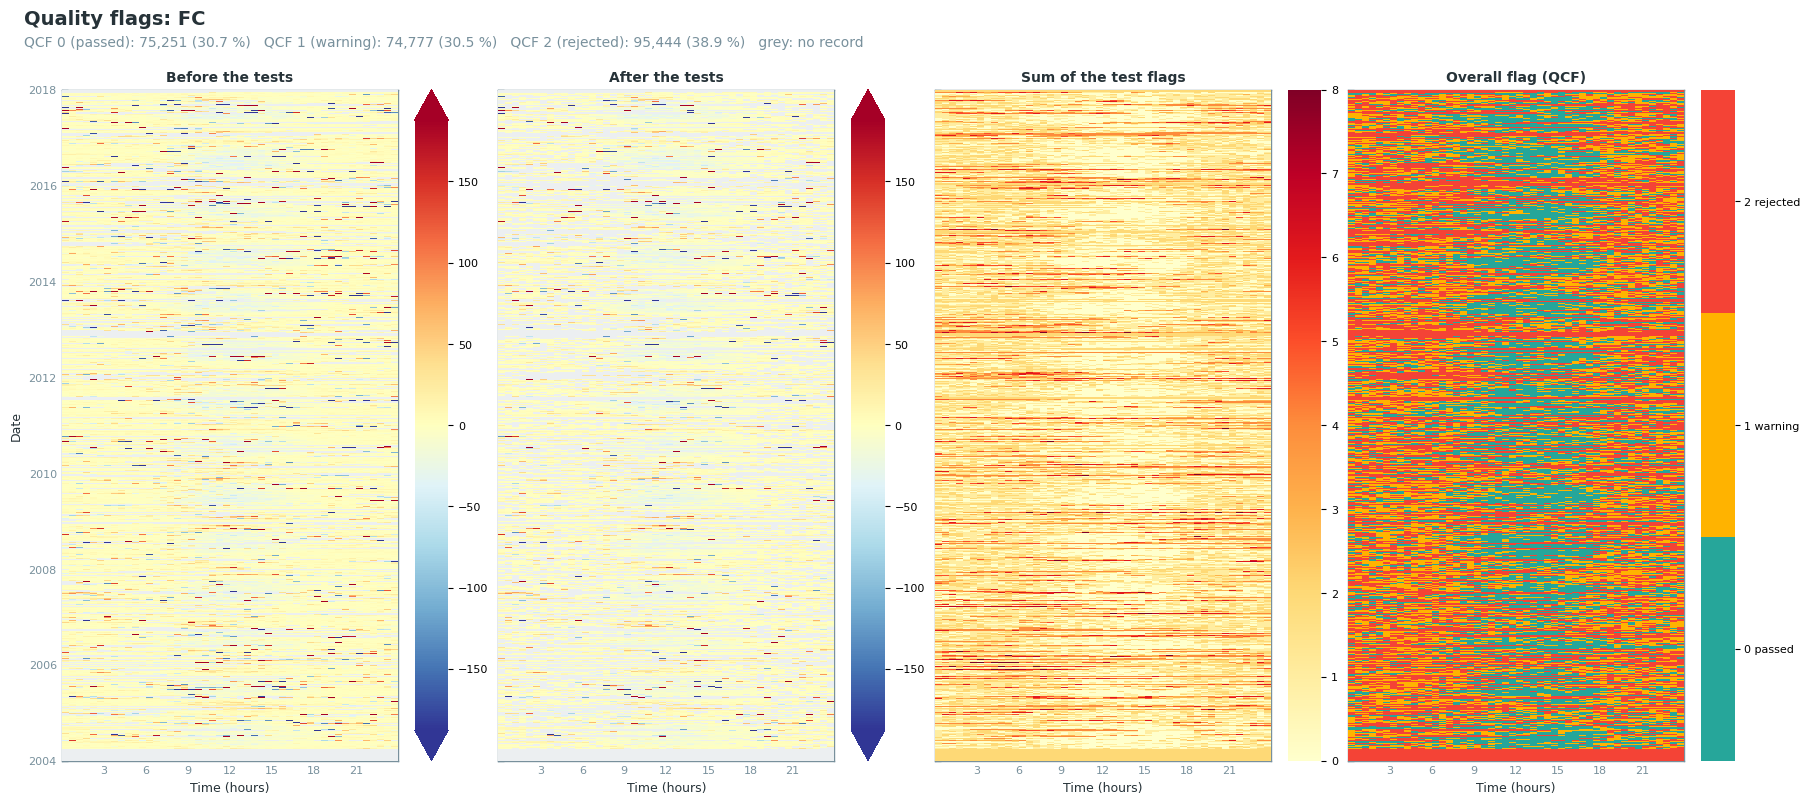

In [6]:
data.levels.level2_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-2 test

In [7]:
data.levels.level2_qcf.report_qcf_flags()

Test flags: FC
Measured records: 197,858 of 245,472
Missing records: 47,614 (19.40 %), flagged by the missing-values test
                                                  Pass     Warn     Fail    Fail      Not
Test                        Period    Tested       (0)      (1)      (2)       %   tested
─────────────────────────────────────────────────────────────────────────────────────────
L2_FC_SSITC                 all      197,858    77,044   79,063   41,751   21.10        0
                            day      100,481    51,863   33,888   14,730   14.66        0
                            night     97,377    25,181   45,175   27,021   27.75        0
                                                                                         
L2_FC_SCF                   all      197,858   197,858        0        0    0.00        0
                            day      100,481   100,481        0        0    0.00        0
                            night     97,377    97,377        0        0    0.00        0
                                                                                         
L2_FC_SIGNAL_STRENGTH       all      197,858   191,183        0    6,675    3.37        0
                            day      100,481    97,401        0    3,080    3.07        0
                            night     97,377    93,782        0    3,595    3.69        0
                                                                                         
L2_FC_CO2_VM97_SPIKE_HF     all      197,858   195,048        0    2,810    1.42        0
                            day      100,481    99,266        0    1,215    1.21        0
                            night     97,377    95,782        0    1,595    1.64        0
                                                                                         
L2_FC_CO2_VM97_DROPOUT_HF   all      197,858   197,858        0        0    0.00        0
                            day      100,481   100,481        0        0    0.00        0
                            night     97,377    97,377        0        0    0.00        0

## Step 3: storage term (Level 3.1)

Adds the storage term to the flux (`FC + SC_SINGLE`), after two screening steps:

- **Next to gaps** in `CO2_CONC`: after a signal loss an analyser can restart far from the real
  concentration, and its return would count as a one-sided storage flux. The storage values are
  discarded until the concentration is normal again for its time of day.
- **Spikes**: each isolated spike, with one record on either side, is replaced by the block mean,
  which keeps the sum.

The removed values are filled with a rolling median, so every measured flux keeps a storage term.
Details: [diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#storage-term).

In [8]:
data = run_level31(data, gapfill_storage_term=True, set_storage_to_zero=False,
                   screen_storage_term=True, concentration_col=CO2_CONC)
print(f'After L3.1: {data.filteredseries.dropna().count():,} valid records '
      f'(col: {data.filteredseries.name})')

────────────────────────────────── Level 3.1: Storage Correction ───────────────────────────────────

> Calculating storage-corrected flux NEE_L3.1 from flux FC + storage term SC_SINGLE

> Storage term SC_SINGLE: 2,652 analyser restart(s) after a gap in CO2_MOLAR_DENSITY; 10,038 
storage value(s) discarded where the concentration was off next to a gap

! Storage term SC_SINGLE: after 3 restart(s) the concentration had not recovered within 48 
records; the screening stopped there.

> Storage term SC_SINGLE: 10,833 spike(s) found (5.36 % of the measured storage values)

> Storage term SC_SINGLE: 23,328 value(s) replaced by the mean of their block (spikes and one 
record on either side)

After L3.1: 150,028 valid records (col: NEE_L3.1_QCF)


### 📊 Plot: storage term screening

The daily cycle should stay positive at night with a dip in the morning, the spikes should have
both signs, and the cumulative sum should stay near zero. A drift that remains usually lies in
periods when the analyser was failing; check that the quality flags remove their fluxes.

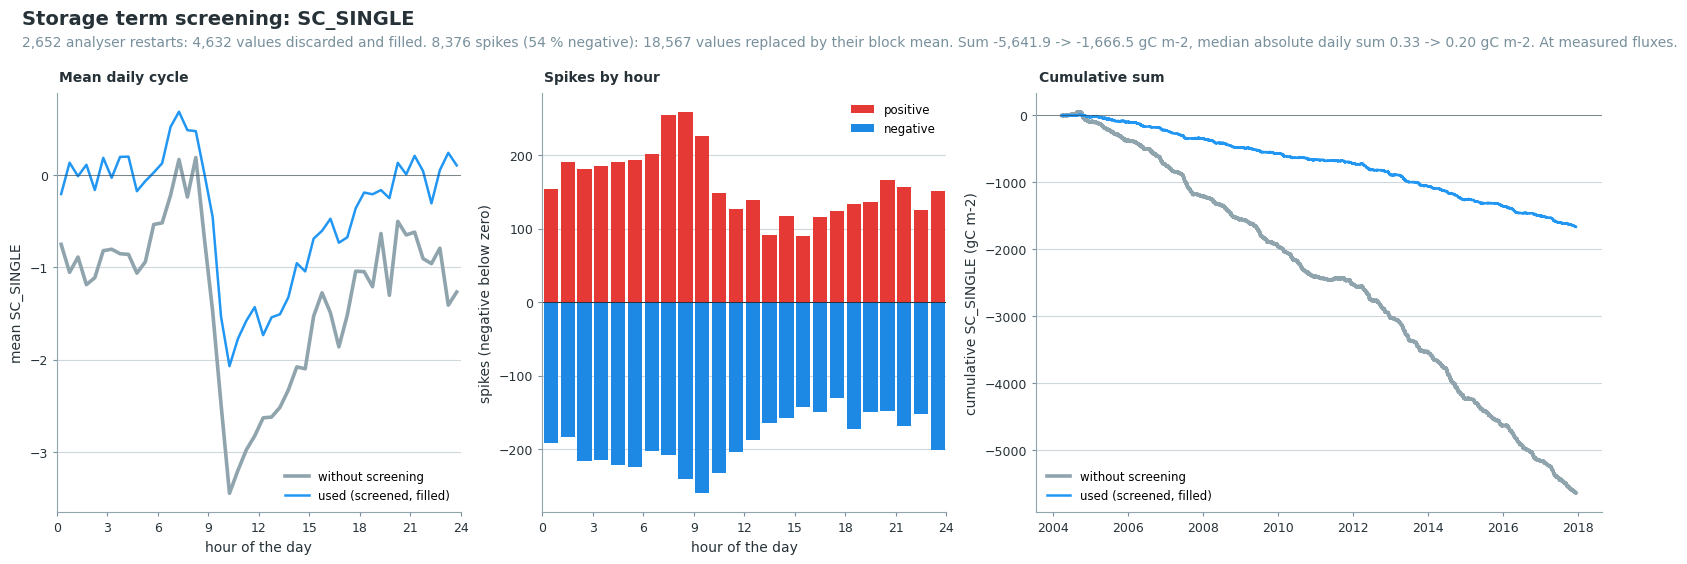

In [9]:
data.levels.level31.plot_screening(gain=UMOL_TO_GC, units='gC m-2');

## Step 4: outlier removal (Level 3.2)

Six tests. Check each plot, then accept the test with `sod.addflag()` in the cell below it.

1. Periods in `REMOVE_DATES`, removed by hand; the reasons are in the site documentation.
2. Absolute limits `ABSLIM`.
3. Hampel filter on double differences: single spikes.
4. Hampel filter per time of day: values wrong for their time of day.
5. Nighttime values clearly below zero.
6. Whole nights whose median lies clearly below zero.

How the tests work: [diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#outlier-tests). The table at the end of this step lists
further tests.

In [10]:
data, sod = make_level32_detector(data)

### 📊 Plot: periods removed by hand

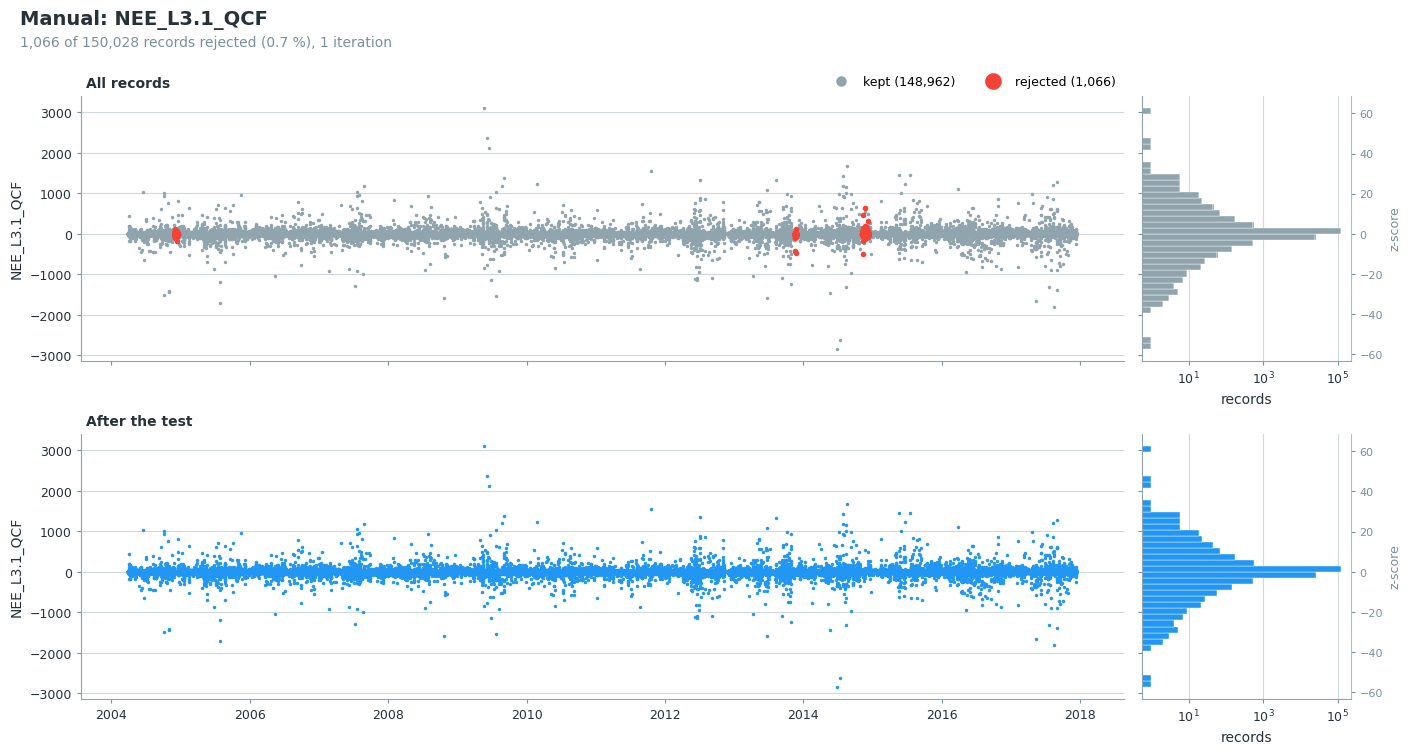

In [11]:
# Only the date ranges that overlap the processed records; none means no test and no flag.
_first, _last = data.full_df.index[0], data.full_df.index[-1]
_remove = [_d for _d in REMOVE_DATES
           if pd.Timestamp(_d[0]) <= _last and pd.Timestamp(_d[1]) + pd.Timedelta('1D') > _first]
if _remove:
    sod.flag_manualremoval_test(remove_dates=_remove, showplot=True, verbose=True)
else:
    print(f"No manual removal dates in {_first:%Y-%m-%d} - {_last:%Y-%m-%d}; test skipped.")

In [12]:
if _remove:
    sod.addflag()  # accept the manual removal

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_MANUAL_TEST to flag data

### 📊 Plot: absolute limits

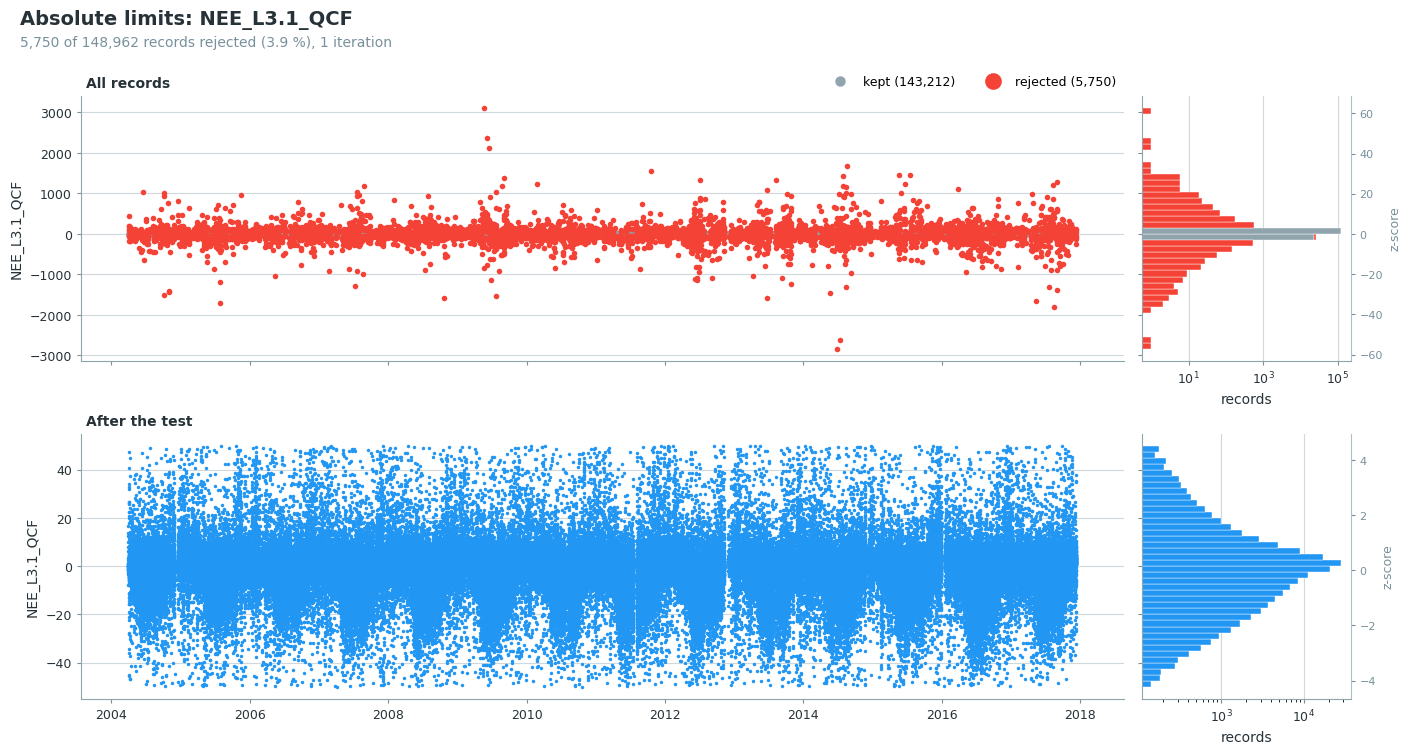

In [13]:
sod.flag_outliers_abslim_test(minval=ABSLIM[0], maxval=ABSLIM[1], showplot=True, verbose=True)

In [14]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_ABSLIM_TEST to flag data

### 📊 Plot: Hampel filter on double differences

[Dt/Nt] ITER #01 | Outliers:  2896 (  2.02%) | Day:   939 | Night:  1957

[Dt/Nt] ITER #02 | Outliers:   379 (  0.27%) | Day:    88 | Night:   291

[Dt/Nt] ITER #03 | Outliers:    49 (  0.04%) | Day:     5 | Night:    44

[Dt/Nt] ITER #04 | Outliers:    18 (  0.01%) | Day:     0 | Night:    18

[Dt/Nt] ITER #05 | Outliers:     3 (  0.00%) | Day:     0 | Night:     3

[Dt/Nt] ITER #06 | Outliers:     3 (  0.00%) | Day:     0 | Night:     3

[Dt/Nt] ITER #07 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

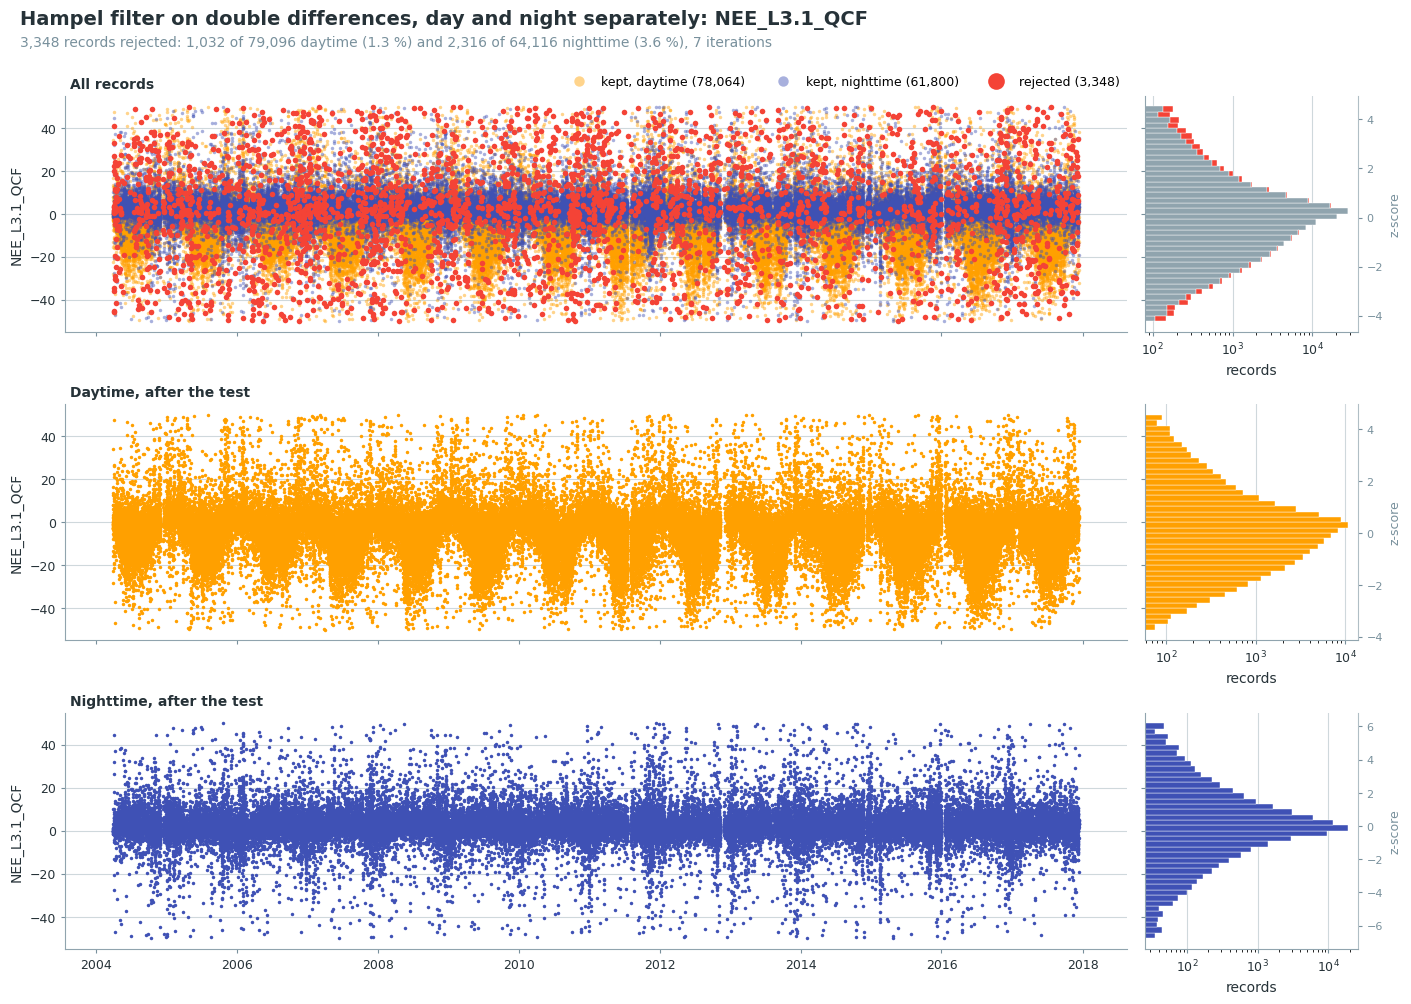

In [15]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=True,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [16]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_TEST to flag data

### 📊 Plot: Hampel filter on values per time of day

[Dt/Nt] ITER #01 | Outliers:  3361 (  2.40%) | Day:  1274 | Night:  2087

[Dt/Nt] ITER #02 | Outliers:   397 (  0.29%) | Day:   146 | Night:   251

[Dt/Nt] ITER #03 | Outliers:    83 (  0.06%) | Day:    29 | Night:    54

[Dt/Nt] ITER #04 | Outliers:    17 (  0.01%) | Day:     8 | Night:     9

[Dt/Nt] ITER #05 | Outliers:     5 (  0.00%) | Day:     3 | Night:     2

[Dt/Nt] ITER #06 | Outliers:     1 (  0.00%) | Day:     1 | Night:     0

[Dt/Nt] ITER #07 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

! Hampel: 806 record(s) were not tested because their time-of-day window held fewer than 
min_records=10 values. They keep flag 0. Consider a longer window_length or more time_of_day_slots.

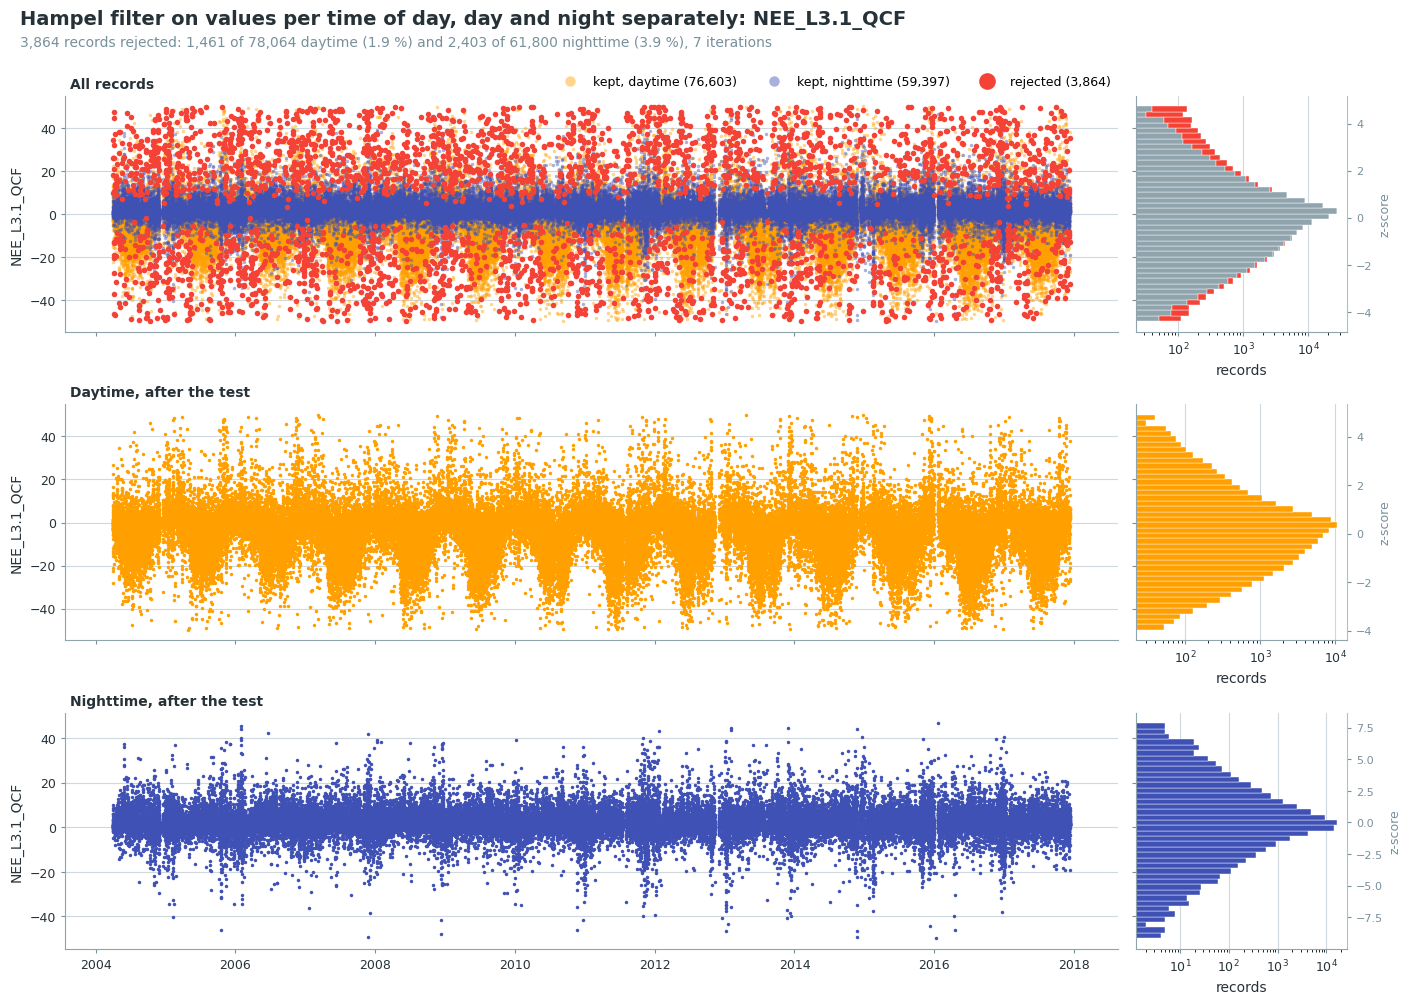

In [17]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=False,
                              by_time_of_day=True, time_of_day_slots=1, min_records=10,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [18]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_2_TEST to flag data

### Negative values at night

At night the flux is respiration, so its true value is zero or above, and only random error pushes
it below zero. Test 5 removes only the values this error cannot explain: nighttime values below
`-NIGHT_Z` times their uncertainty `NIGHT_UNC`. `NIGHT_UNC` is the larger of the EddyPro random
uncertainty `FS` of the record and the median `PAS20` uncertainty (ONEFlux) of the nighttime
records of the same calendar month over all years, combined in quadrature with the uncertainty of
the opco correction, `OPCO_SIGMA`. `FS` covers only the sampling error of the covariance and is too
small on its own. `PAS20` covers the total random error, but in a noisy stretch, e.g. in fog on the
windows, the bad values widen it and pass the test; the monthly median does not grow with them.
With `NIGHT_Z = 4`, a random error of the shape of eddy-covariance errors (Laplace) exceeds the
limit with a probability of at most 0.2 % per record, a Gaussian one with 0.003 %. High values are
not tested ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#negative-nighttime)).

### 📋 Table: random uncertainty of the nighttime records

In [19]:
sigma = nighttime_uncertainty(data, sod, randunc_col=RANDUNC_COL, ta=TA_F, vpd=VPD_F, swin=SW_IN_F)

# Uncertainty of each record for tests 5 and 6: the larger of FS and the median PAS20 of the
# nighttime records of the same calendar month, over all years, combined in quadrature with the
# uncertainty of the opco correction (see Settings).
_night = (data.fpc_df['NIGHTTIME'].reindex(sigma.index) == 1) & sigma['PAS20'].notna()
_pas20_month = sigma.loc[_night, 'PAS20'].groupby(sigma.index[_night].month).median()
_pas20_typical = (pd.Series(sigma.index.month, index=sigma.index).map(_pas20_month)
                  .where(sigma['PAS20'].notna()))
night_unc = np.sqrt(np.fmax(sigma['FS'], _pas20_typical) ** 2 + OPCO_SIGMA ** 2).rename('NIGHT_UNC')
print(f"Median PAS20 of the nighttime records per calendar month ({FLUX_UNITS}): "
      + ", ".join(f"{_m}: {_v:.2f}" for _m, _v in _pas20_month.items()))
print(f"NIGHT_UNC, median at night: {night_unc[_night].median():.2f} {FLUX_UNITS}")

Random uncertainty of the 59,397 nighttime records
uncertainty   median at night   below -2 sigma   below -3 sigma
───────────────────────────────────────────────────────────────
FS                       0.93   8,061 (13.6 %)    5,439 (9.2 %)
PAS20                    4.08      865 (1.5 %)       92 (0.2 %)
MAX                      4.13      674 (1.1 %)       51 (0.1 %)
POOLED                   3.19    2,374 (4.0 %)    1,225 (2.1 %)
FS: EddyPro, sampling error of each half-hour. PAS20: spread of similar measurements (ONEFlux), a 
generous estimate. MAX: the larger of the two. POOLED: spread of all nighttime values within 15 days
on either side.

### 📊 Plot: nighttime values clearly below zero

> Nighttime records below -4 uncertainties: 663. Expected from noise alone (Gaussian): 0.3 
records, raising the sum by 4.99 (flux units x records) once their gaps are filled.

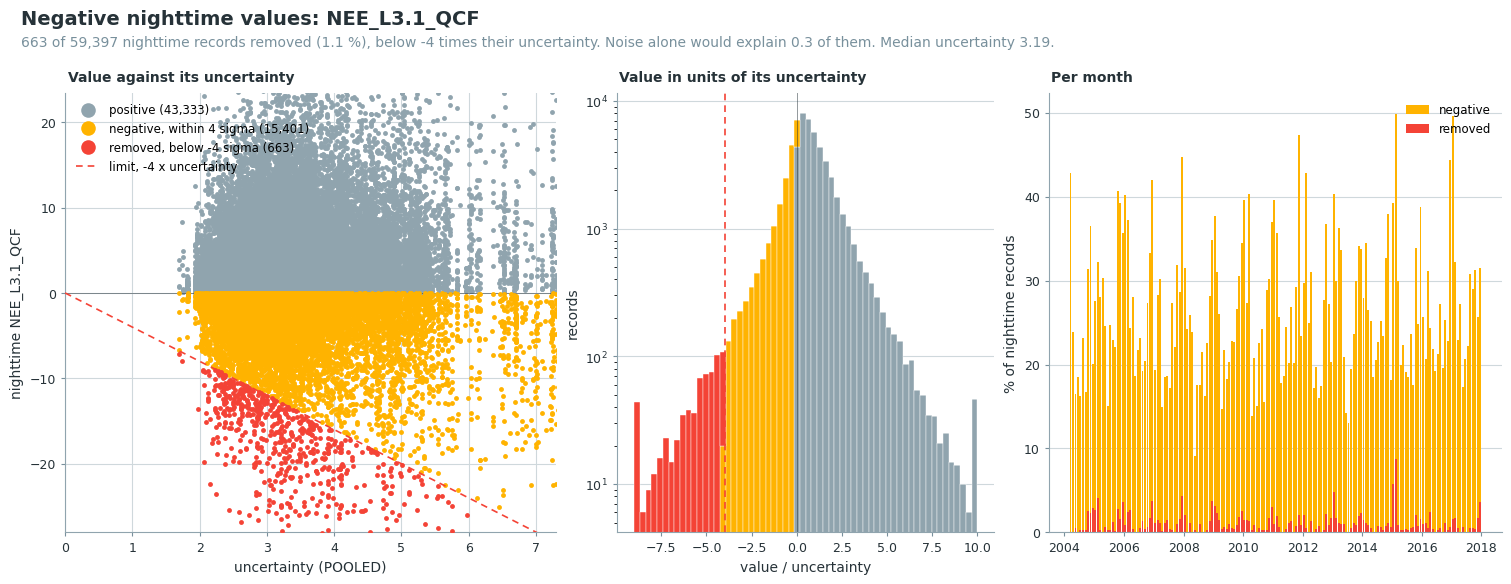

In [20]:
sod.flag_outliers_negative_night_test(uncertainty=night_unc, z=NIGHT_Z, showplot=True, verbose=True)

In [21]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_NEGNIGHT_TEST to flag data

### Nights shifted below zero

Test 5 tests each record on its own and lets through a night that is shifted below zero as a whole: in fog or rime on the open-path windows the LI-7500 reads uptake for hours, each record within a few uncertainties of zero. Test 6 removes every record of a night whose median lies below `-NIGHTS_Z` standard errors of that median. The standard error combines two parts in quadrature. The random part is √(π/2) times the median `NIGHT_UNC` of the night over √n, with n reduced to the number of independent records, n (1 − r) / (1 + r), for the lag-1 autocorrelation r = `NIGHTS_AUTOCORR` of the nighttime values. The second part is `OPCO_SIGMA`: an error of the opco correction is shared by the records of a night and does not average out. With `NIGHTS_Z = 3` the test removes clearly wrong nights, not slightly negative ones. Nights with fewer than `NIGHTS_MIN_RECORDS` values are not tested ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#negative-nights)).

### 📊 Plot: nights shifted below zero

> Nights with a median below -2 standard errors: 75 of 3,903 tested nights, 1,150 records.

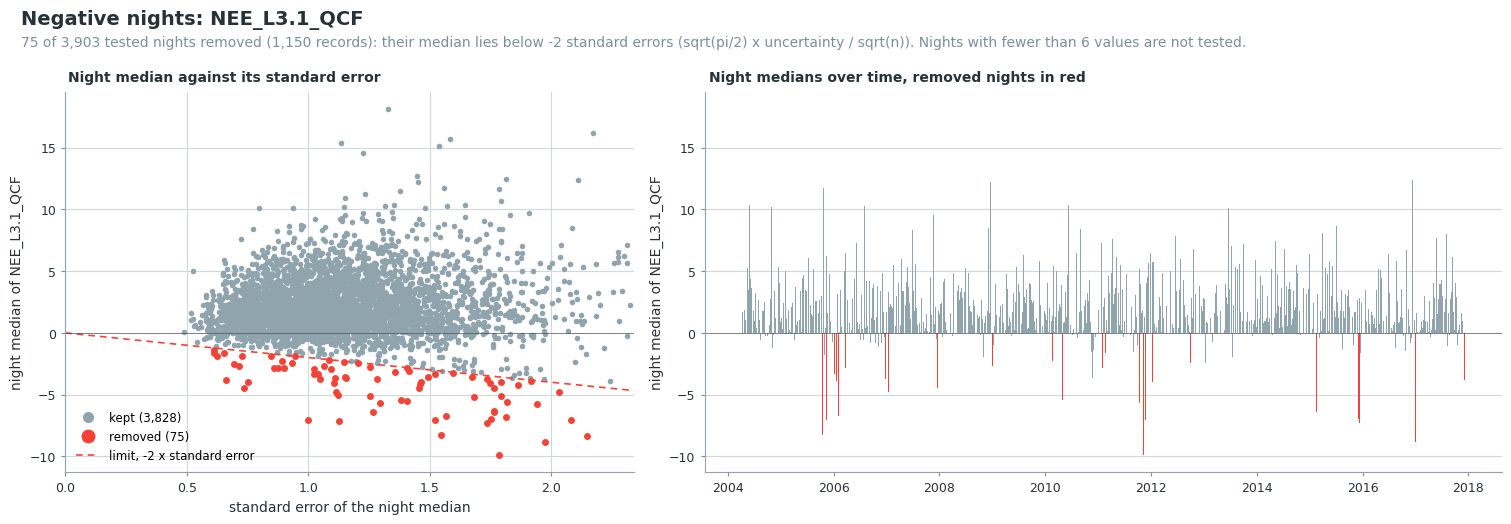

In [22]:
# Check of NIGHTS_AUTOCORR: lag-1 autocorrelation of the nighttime values about their night median.
_s = sod.series_hires_cleaned
_v = _s[(data.fpc_df['NIGHTTIME'].reindex(_s.index) == 1) & _s.notna()]
_dev = _v - _v.groupby(night_of(_v.index)).transform('median')
_r = _dev.corr(_dev.groupby(night_of(_dev.index)).shift(1))
print(f"Lag-1 autocorrelation of the nighttime values about their night median: {_r:.2f} "
      f"(NIGHTS_AUTOCORR = {NIGHTS_AUTOCORR})")
# Widening the record uncertainty by sqrt((1 + r) / (1 - r)) gives the standard error of
# n (1 - r) / (1 + r) independent records.
_nights_unc = (night_unc * np.sqrt((1 + NIGHTS_AUTOCORR) / (1 - NIGHTS_AUTOCORR))).rename('NIGHT_UNC')
sod.flag_outliers_negative_nights_test(uncertainty=_nights_unc, z=NIGHTS_Z, min_records=NIGHTS_MIN_RECORDS,
                                       systematic=OPCO_SIGMA, showplot=True, verbose=True)

In [23]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_NEGNIGHTS_TEST to flag data

### 📋 Table: outlier tests available in diive

Every test of the outlier detector `sod`, with the ones used above marked. `help(sod.<method>)`
shows the settings of a test.

In [24]:
_used = {'flag_manualremoval_test', 'flag_outliers_abslim_test', 'flag_outliers_hampel_test',
         'flag_outliers_negative_night_test',
         'flag_outliers_negative_nights_test'}
_rows = []
for _name in sorted(dir(type(sod))):
    if not (_name.startswith('flag_') and _name.endswith('_test')):
        continue
    # The first sentence of the docstring, which may run over two lines.
    _doc = (getattr(type(sod), _name).__doc__ or '').strip().split('\n\n')[0]
    _first = ' '.join(_doc.split()).split('. ')[0].rstrip('.')
    _rows.append({'method': f'sod.{_name}()', 'what it does': _first,
                  'used here': 'yes' if _name in _used else ''})
display(pd.DataFrame(_rows).set_index('method'))

,what it does,used here
method,,
sod.flag_manualremoval_test(),Flag specified records for removal,yes
sod.flag_missingvals_test(),Flag missing records in the data (flag 2 where...,
sod.flag_outliers_abslim_test(),Identify outliers based on absolute limits,yes
sod.flag_outliers_hampel_test(),Identify outliers in a sliding window based on...,yes
sod.flag_outliers_increments_zcore_test(),Identify outliers based on the z-score of reco...,
sod.flag_outliers_localsd_test(),Identify outliers based on standard deviation ...,
sod.flag_outliers_lof_test(),Local outlier factor detection (global or sepa...,
sod.flag_outliers_negative_night_test(),Flag nighttime values below -z times their ran...,yes
sod.flag_outliers_negative_nights_test(),Flag all records of nights whose median lies b...,yes


### Apply the Level-3.2 flags

In [25]:
data = run_level32(data, outlier_detector=sod)
print(f'After L3.2: {data.filteredseries.dropna().count():,} valid records')

────────────────────────────── Level 3.2: Stepwise Outlier Detection ───────────────────────────────

After L3.2: 134,187 valid records


### 📊 Plot: all removed outliers

Every record Level 3.2 removed, coloured by the test that removed it, with the share removed per
month and per hour of the day.

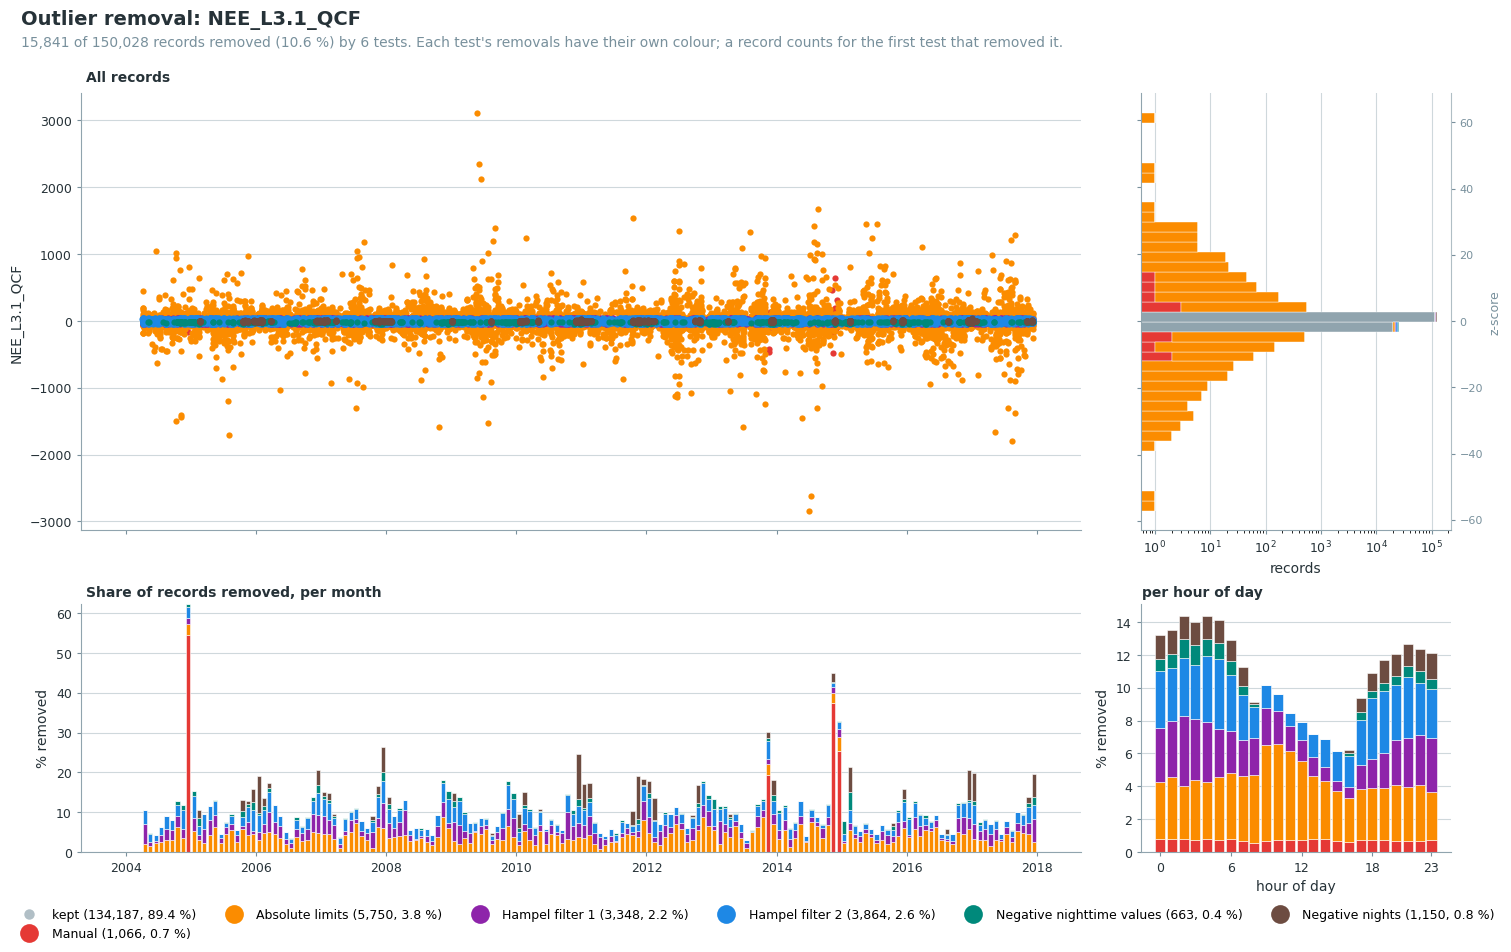

In [26]:
data.levels.level32.showplot_overview();

### 📊 Plot: Level-3.2 quality flag over time

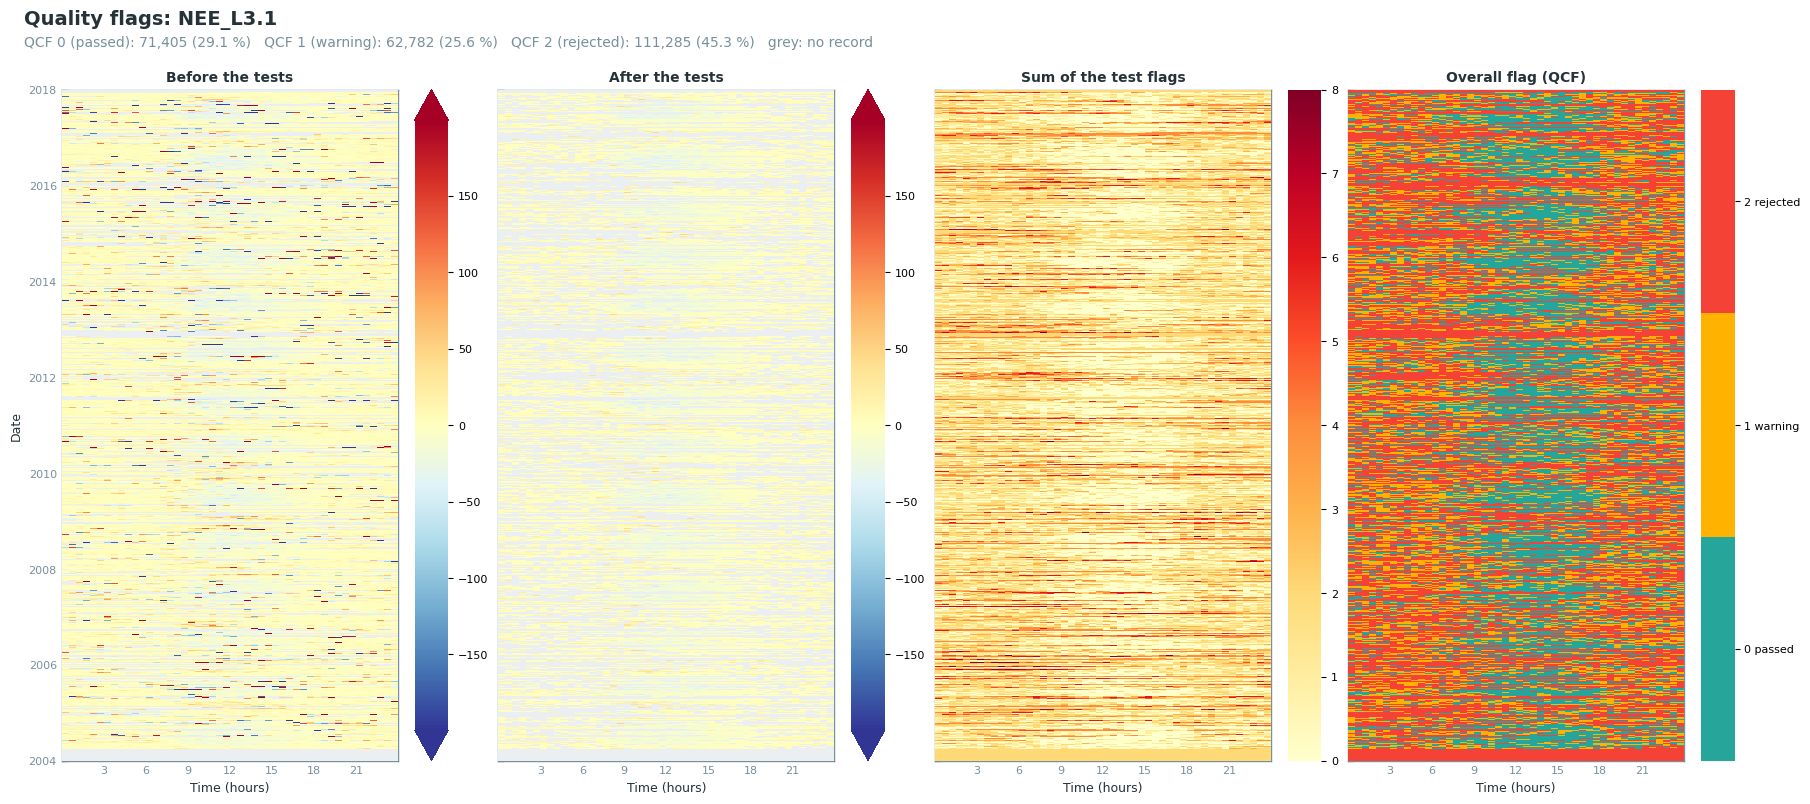

In [27]:
data.levels.level32_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-3.2 test

In [28]:
data.levels.level32_qcf.report_qcf_flags()

Test flags: NEE_L3.1
Measured records: 197,858 of 245,472
Missing records: 47,614 (19.40 %), flagged by the missing-values test
                                                            Pass     Warn     Fail    Fail      Not
Test                                  Period    Tested       (0)      (1)      (2)       %   tested
───────────────────────────────────────────────────────────────────────────────────────────────────
L2_FC_SSITC                           all      197,858    77,044   79,063   41,751   21.10        0
                                      day      100,481    51,863   33,888   14,730   14.66        0
                                      night     97,377    25,181   45,175   27,021   27.75        0
                                                                                                   
L2_FC_SCF                             all      197,858   197,858        0        0    0.00        0
                                      day      100,481   100,481        0        0    0.00        0
                                      night     97,377    97,377        0        0    0.00        0
                                                                                                   
L2_FC_SIGNAL_STRENGTH                 all      197,858   191,183        0    6,675    3.37        0
                                      day      100,481    97,401        0    3,080    3.07        0
                                      night     97,377    93,782        0    3,595    3.69        0
                                                                                                   
L2_FC_CO2_VM97_SPIKE_HF               all      197,858   195,048        0    2,810    1.42        0
                                      day      100,481    99,266        0    1,215    1.21        0
                                      night     97,377    95,782        0    1,595    1.64        0
                                                                                                   
L2_FC_CO2_VM97_DROPOUT_HF             all      197,858   197,858        0        0    0.00        0
                                      day      100,481   100,481        0        0    0.00        0
                                      night     97,377    97,377        0        0    0.00        0
                                                                                                   
L3.2_NEE_L3.1_QCF_OUTLIER_MANUAL      all      150,028   148,962        0    1,066    0.71   47,830
                                      day       82,995    82,570        0      425    0.51   17,486
                                      night     67,033    66,392        0      641    0.96   30,344
                                                                                                   
L3.2_NEE_L3.1_QCF_OUTLIER_ABSLIM      all      148,962   143,212        0    5,750    3.86   48,896
                                      day       82,570    79,096        0    3,474    4.21   17,911
                                      night     66,392    64,116        0    2,276    3.43   30,985
                                                                                                   
L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL      all      143,212   139,864        0    3,348    2.34   54,646
                                      day       79,096    78,064        0    1,032    1.30   21,385
                                      night     64,116    61,800        0    2,316    3.61   33,261
                                                                                                   
L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_2    all      139,864   136,000        0    3,864    2.76   57,994
                                      day       78,064    76,603        0    1,461    1.87   22,417
                                      night     61,800    59,397        0    2,403    3.89   35,577
                                                                        

## Step 5: USTAR filter (Level 3.3)

Removes records with USTAR below the threshold, by day and by night; unlike ONEFlux, the first
record above it is kept. One scenario per threshold in `USTAR_THRESHOLDS`
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#ustar-filter)).

In [29]:
data = run_level33_constant_ustar(
    data,
    thresholds=USTAR_THRESHOLDS,
    threshold_labels=USTAR_SCENARIOS,
    showplot=False,
    verbose=True,
)

──────────────────────────────────── Level 3.3: USTAR Filtering ────────────────────────────────────

> QCF computed for USTAR scenario CUT_16

> QCF computed for USTAR scenario CUT_50

> QCF computed for USTAR scenario CUT_84

### Records for gap-filling and highest-quality records

The records the gap-filling starts from (QCF 0 and 1, columns `_QCF`) and the highest-quality
records (QCF 0, columns `_QCF0`) for analyses without gap-filled values
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#gapfilling-input)).

### 📋 Table: records per USTAR scenario

In [30]:
report_gapfilling_input(data);

Records for gap-filling
                    removed:   removed:             used:    used:    used:    used:
USTAR    measured      tests      USTAR     used    QCF 0    QCF 1      day    night
────────────────────────────────────────────────────────────────────────────────────
CUT_16    197,858     63,671     35,359   98,828   61,048   37,780   62,162   36,666
              81%        26%        14%      40%      25%      15%      25%      15%
CUT_50    197,858     63,671     41,640   92,547   58,186   34,361   58,701   33,846
              81%        26%        17%      38%      24%      14%      24%      14%
CUT_84    197,858     63,671     48,606   85,581   54,709   30,872   54,700   30,881
              81%        26%        20%      35%      22%      13%      22%      13%
Records, and their share of all 245,472 records of the period.
removed: tests = quality tests and outlier detection (Levels 2 to 3.2).
used = records for gap-filling: QCF below 2 by day and below 2 by night. QCF 0 is the highest 
quality, the measured flux for analyses without gap-filled values.

### 📊 Plot: records for gap-filling and highest-quality records

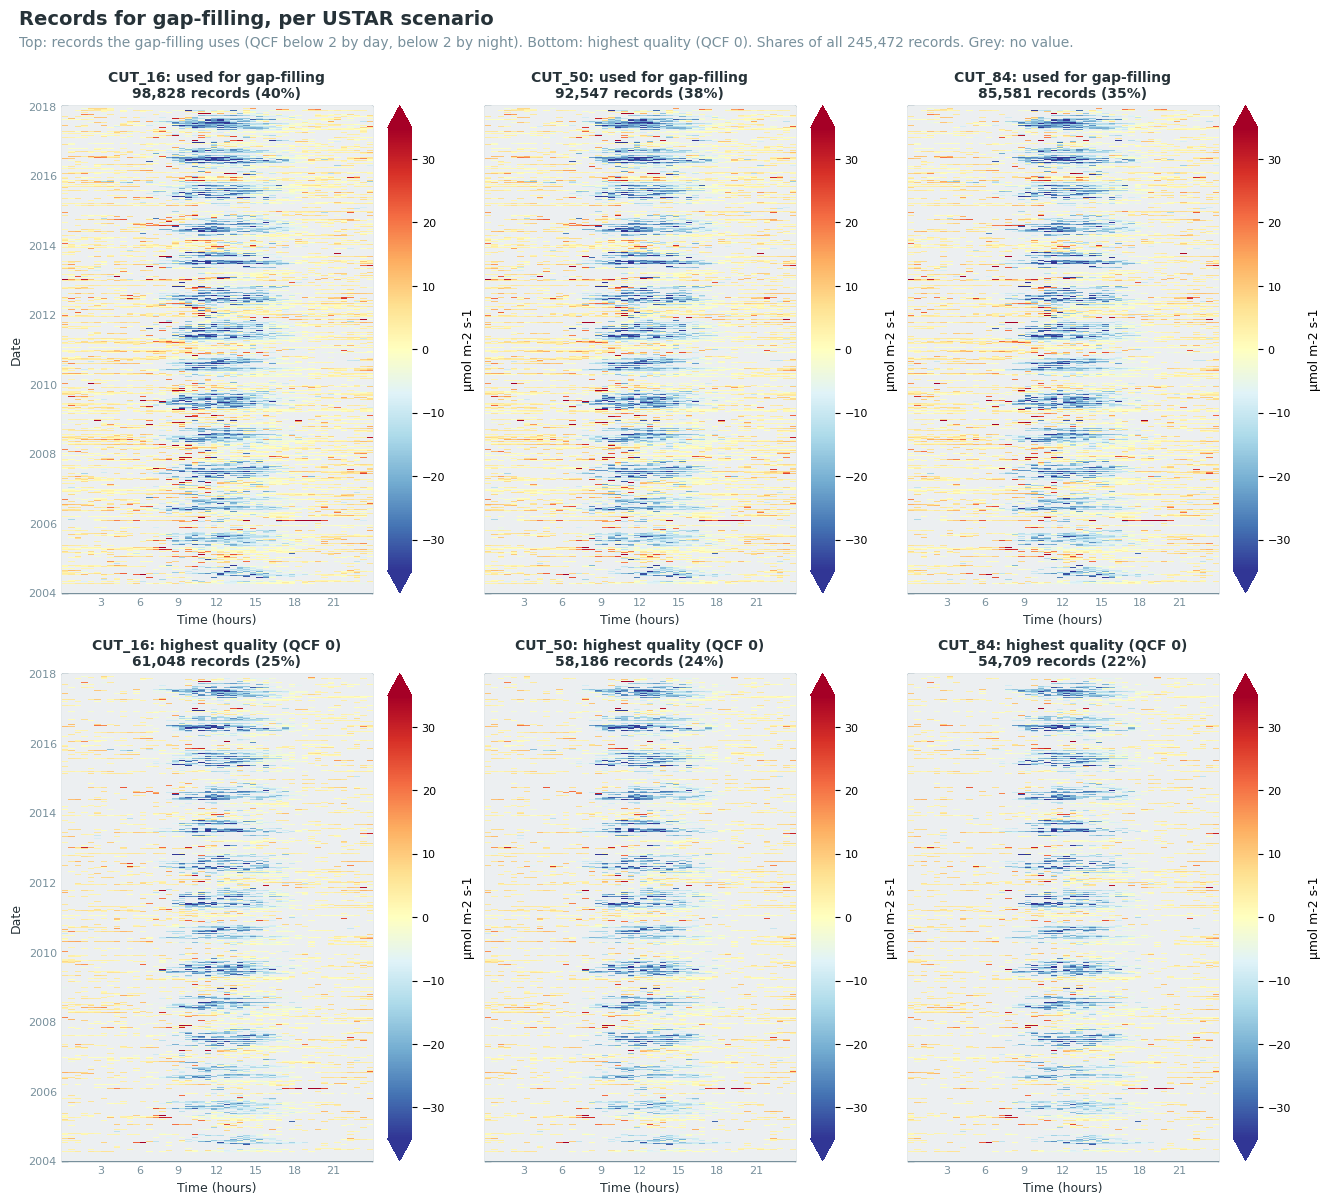

In [31]:
plot_gapfilling_input(data, units=FLUX_UNITS)

### 📋 Table: gaps per USTAR scenario

The gaps left after Level 3.3, which the gap-filling has to fill. A long gap lasts at least one day.

In [32]:
report_gaps(data, long_gap_days=1);

Gaps to fill
USTAR    missing %    gaps   long gaps   longest gap (days)   worst month   worst month missing %
─────────────────────────────────────────────────────────────────────────────────────────────────
CUT_16        59.7   24838         278                 90.5           Dec                    70.7
CUT_50        62.3   23740         311                 90.5           Jan                    72.5
CUT_84        65.1   22479         347                 90.5           Jan                    74.7
A long gap lasts at least 1 day.

## Step 6: meteo drivers and model features

The ONEFlux partitioning needs measured temperature and radiation. These are the complete driver
series, restricted to the measured records. `add_driver` puts them into `data.full_df`,
where Levels 4.1 and 4.2 look for their drivers.

The feature engineer adds lagged values, rolling statistics and time terms to the drivers. It is
built once and passed to XGBoost. `target_col` is only a placeholder.

In [33]:
_ta_meas = df[TA_F].where(df[TA_FLAG] == 0).rename(TA_MEAS)
_sw_meas = df[SW_IN_F].where(df[SW_IN_FLAG] == 0).rename(SW_IN_MEAS)
data = add_driver(data, _ta_meas)
data = add_driver(data, _sw_meas)
print(f"{TA_MEAS}: {_ta_meas.notna().sum():,} measured records of {len(_ta_meas):,}")
print(f"{SW_IN_MEAS}: {_sw_meas.notna().sum():,} measured records of {len(_sw_meas):,}")

engineer = FeatureEngineer(
    target_col='_target_',
    features_lag=[-2, 2],
    features_lag_stepsize=1,
    features_rolling=[2, 4, 12, 24, 48],
    features_rolling_stats=['median', 'min', 'max', 'std'],
    features_ema=[6, 12, 24, 48],
    vectorize_timestamps=True,
    add_continuous_record_number=True,
    sanitize_timestamp=True,
    verbose=0,
)

TA_T1_47_1_HOMOGENIZED_MEASURED: 229,684 measured records of 245,472
SW_IN_T1_47_1_MEASURED: 212,319 measured records of 245,472


## Step 7: gap-filling (Level 4.1)

XGBoost fills the gaps of this dataset, MDS for comparison (Step 11).

### XGBoost

One model per year and USTAR scenario, trained on three years, with features selected by SHAP and
shared across the scenarios ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#xgboost-gapfilling)).

The number of trees is chosen once for all models by blocked cross-validation
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#tree-selection)).

In [34]:
data = run_level41_xgb(
    data,
    features=FEATURES,
    engineer=engineer,
    reduce_features=True,
    n_estimators_cv=True,
    verbose=1,
    **XGB_SETTINGS,
)

───────────────────────────────── Level 4.1: Gap-Filling (XGBoost) ─────────────────────────────────

### MDS

Marginal distribution sampling (Reichstein et al. 2005) in `mode='diive'`, filling every gap from
measured driver values only ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#mds-gapfilling)).

**Skipped** when `RUN_MDS = False`.

In [35]:
if RUN_MDS:
    data = run_level41_mds(
        data,
        swin=SW_IN_F, ta=TA_F, vpd=VPD_F,  # W m-2, degC, kPa
        swin_qc=SW_IN_FLAG, ta_qc=TA_FLAG, vpd_qc=VPD_FLAG,
        **MDS_SETTINGS,
    )

─────────────────────────────────── Level 4.1: Gap-Filling (MDS) ───────────────────────────────────

## Step 8: partitioning into GPP and RECO (Level 4.2)

**Skipped** when `RUN_PARTITIONING = False`. Nighttime and daytime partitioning as in ONEFlux
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#partitioning)).

In [36]:
if RUN_PARTITIONING:
    data = run_level42_partitioning(
        data,
        method='nighttime',
        mode='oneflux',
        ta=TA_MEAS,
        sw_in=SW_IN_MEAS,
        ta_f=TA_F,
        gapfill_method='xgb',
    )

───────────────── Level 4.2: NEE Partitioning (Nighttime ONEFlux, Reichstein 2005) ─────────────────

In [37]:
if RUN_PARTITIONING:
    data = run_level42_partitioning(
        data,
        method='daytime',
        mode='oneflux',
        ta=TA_MEAS,
        sw_in=SW_IN_MEAS,
        ta_f=TA_F,
        sw_in_f=SW_IN_F,
        vpd_f=VPD_F,  # kPa
        gapfill_method='xgb',
    )
    print(data.partitioned_cols())

─────────────────── Level 4.2: NEE Partitioning (Daytime ONEFlux, Lasslop 2010) ────────────────────

! Daytime partitioning (ONEFlux): no light-response curve could be fitted; year left 
unpartitioned.

! Daytime partitioning (ONEFlux): no light-response curve could be fitted; year left 
unpartitioned.

! Daytime partitioning (ONEFlux): no light-response curve could be fitted; year left 
unpartitioned.

{'nt_of': {'CUT_16': ['NEE_NIGHT_OF_CUT_16', 'RECO_NT_OF_CUT_16', 'RECO_NT_OF_ROB_CUT_16', 'GPP_NT_OF_CUT_16', 'GPP_NT_OF_ROB_CUT_16', 'RREF_NT_OF_CUT_16', 'E0_NT_OF_CUT_16'], 'CUT_50': ['NEE_NIGHT_OF_CUT_50', 'RECO_NT_OF_CUT_50', 'RECO_NT_OF_ROB_CUT_50', 'GPP_NT_OF_CUT_50', 'GPP_NT_OF_ROB_CUT_50', 'RREF_NT_OF_CUT_50', 'E0_NT_OF_CUT_50'], 'CUT_84': ['NEE_NIGHT_OF_CUT_84', 'RECO_NT_OF_CUT_84', 'RECO_NT_OF_ROB_CUT_84', 'GPP_NT_OF_CUT_84', 'GPP_NT_OF_ROB_CUT_84', 'RREF_NT_OF_CUT_84', 'E0_NT_OF_CUT_84']}, 'dt_of': {'CUT_16': ['RECO_DT_OF_CUT_16', 'GPP_DT_OF_CUT_16', 'SE_GPP_DT_OF_CUT_16', 'ALPHA_DT_OF_CUT_16', 'BETA_DT_OF_CUT_16', 'K_DT_OF_CUT_16', 'RREF_DT_OF_CUT_16', 'E0_DT_OF_CUT_16'], 'CUT_50': ['RECO_DT_OF_CUT_50', 'GPP_DT_OF_CUT_50', 'SE_GPP_DT_OF_CUT_50', 'ALPHA_DT_OF_CUT_50', 'BETA_DT_OF_CUT_50', 'K_DT_OF_CUT_50', 'RREF_DT_OF_CUT_50', 'E0_DT_OF_CUT_50'], 'CUT_84': ['RECO_DT_OF_CUT_84', 'GPP_DT_OF_CUT_84', 'SE_GPP_DT_OF_CUT_84', 'ALPHA_DT_OF_CUT_84', 'BETA_DT_OF_CUT_84', 'K_DT_OF_CU

## Step 9: results

How many records were measured and how many were filled, then the annual sum of the flux, for each
USTAR scenario. The share measured is given in brackets: a year with long gaps rests largely on the
model. An incomplete year is marked.

### 📋 Table: measured and filled records

In [38]:
report_gapfilling_variables(data)

Gap-filled variables
method    USTAR    records   measured    filled   filled %
──────────────────────────────────────────────────────────
MDS       CUT_16   245,472     98,828   146,644       59.7
MDS       CUT_50   245,472     92,547   152,925       62.3
MDS       CUT_84   245,472     85,581   159,891       65.1
XGBoost   CUT_16   245,472     98,828   146,644       59.7
XGBoost   CUT_50   245,472     92,547   152,925       62.3
XGBoost   CUT_84   245,472     85,581   159,891       65.1
MDS (CUT_16): NEE_L3.1_L3.3_CUT_16_QCF -> NEE_L3.1_L3.3_CUT_16_QCF_gfMDS
MDS (CUT_50): NEE_L3.1_L3.3_CUT_50_QCF -> NEE_L3.1_L3.3_CUT_50_QCF_gfMDS
MDS (CUT_84): NEE_L3.1_L3.3_CUT_84_QCF -> NEE_L3.1_L3.3_CUT_84_QCF_gfMDS
XGBoost (CUT_16): NEE_L3.1_L3.3_CUT_16_QCF -> NEE_L3.1_L3.3_CUT_16_QCF_gfXG
XGBoost (CUT_50): NEE_L3.1_L3.3_CUT_50_QCF -> NEE_L3.1_L3.3_CUT_50_QCF_gfXG
XGBoost (CUT_84): NEE_L3.1_L3.3_CUT_84_QCF -> NEE_L3.1_L3.3_CUT_84_QCF_gfXG

### 📋 Table: annual sums of the flux

In [39]:
report_annual_sums(data, gain=UMOL_TO_GC, units='gC m-2');

Annual sums (gC m-2)
              MDS          MDS          MDS      XGBoost      XGBoost      XGBoost
year       CUT_16       CUT_50       CUT_84       CUT_16       CUT_50       CUT_84
──────────────────────────────────────────────────────────────────────────────────
2004      5 (33%)     33 (31%)     -7 (29%)    139 (33%)    161 (31%)    157 (29%)
2005     78 (39%)    132 (36%)    158 (33%)    118 (39%)    164 (36%)    211 (33%)
2006    183 (41%)    218 (38%)    262 (35%)     92 (41%)    144 (38%)    186 (35%)
2007    -81 (44%)    -62 (41%)    -46 (39%)   -126 (44%)   -101 (41%)    -64 (39%)
2008     79 (44%)    112 (42%)    145 (39%)     30 (44%)     64 (42%)     78 (39%)
2009     62 (42%)     83 (39%)    113 (35%)     26 (42%)     59 (39%)     97 (35%)
2010     22 (39%)     32 (36%)     62 (33%)    -45 (39%)    -44 (36%)    -18 (33%)
2011   -266 (42%)   -217 (39%)   -222 (36%)   -265 (42%)   -218 (39%)   -190 (36%)
2012   -361 (36%)   -348 (34%)   -339 (31%)   -241 (36%)   -219 (34%)   -209 (31%)
2013    -61 (39%)    -27 (37%)    -27 (34%)   -197 (39%)   -163 (37%)   -160 (34%)
2014   -109 (41%)   -109 (38%)    -71 (35%)   -208 (41%)   -221 (38%)   -177 (35%)
2015   -183 (43%)   -165 (40%)   -133 (37%)   -158 (43%)   -167 (40%)   -129 (37%)
2016   -180 (42%)   -175 (39%)   -136 (36%)   -326 (42%)   -326 (39%)   -277 (36%)
2017   -160 (40%)   -111 (38%)    -94 (35%)   -165 (40%)   -128 (38%)   -121 (35%)
In brackets: the share of the year's records that were measured.

## Step 10: model quality

First the scores on test data: a random 25 % of the complete records, which the model did not see in
training. The number of trees is chosen without the test data. Because the test
records lie between training records, the scores describe short gaps better than gaps of several
days.

### 📋 Table: scores on test data

In [40]:
report_traintest_model_scores(data)

Held-out test scores
method    USTAR    year      R²   RMSE    MAE   MedAE   MaxE
────────────────────────────────────────────────────────────
XGBoost   CUT_16   2004   0.558   6.36   4.17    2.62   46.5
XGBoost   CUT_16   2005   0.558   6.36   4.17    2.62   46.5
XGBoost   CUT_16   2006   0.563   6.60   4.28    2.65   45.8
XGBoost   CUT_16   2007   0.589   6.52   4.21    2.59   50.8
XGBoost   CUT_16   2008   0.608   6.61   4.23    2.58   50.1
XGBoost   CUT_16   2009   0.613   6.48   4.16    2.58   49.5
XGBoost   CUT_16   2010   0.610   6.74   4.32    2.66   51.7
XGBoost   CUT_16   2011   0.600   6.89   4.44    2.72   49.6
XGBoost   CUT_16   2012   0.593   7.34   4.76    2.90   48.9
XGBoost   CUT_16   2013   0.587   7.24   4.79    3.01   52.1
XGBoost   CUT_16   2014   0.586   7.23   4.81    3.02   50.6
XGBoost   CUT_16   2015   0.604   7.11   4.74    3.07   45.7
XGBoost   CUT_16   2016   0.614   6.96   4.60    2.91   44.6
XGBoost   CUT_16   2017   0.614   6.96   4.60    2.91   44.6
XGBoost   CUT_16   mean   0.593   6.81   4.45    2.77   48.4
                                                            
XGBoost   CUT_50   2004   0.563   6.39   4.18    2.65   47.1
XGBoost   CUT_50   2005   0.563   6.39   4.18    2.65   47.1
XGBoost   CUT_50   2006   0.571   6.61   4.30    2.67   42.6
XGBoost   CUT_50   2007   0.594   6.55   4.23    2.58   51.0
XGBoost   CUT_50   2008   0.613   6.66   4.26    2.59   50.2
XGBoost   CUT_50   2009   0.621   6.50   4.16    2.55   49.8
XGBoost   CUT_50   2010   0.617   6.75   4.33    2.67   50.4
XGBoost   CUT_50   2011   0.608   6.88   4.44    2.74   46.5
XGBoost   CUT_50   2012   0.598   7.37   4.79    2.93   50.0
XGBoost   CUT_50   2013   0.591   7.29   4.80    2.99   51.1
XGBoost   CUT_50   2014   0.590   7.28   4.84    3.07   50.0
XGBoost   CUT_50   2015   0.612   7.12   4.75    3.00   46.3
XGBoost   CUT_50   2016   0.622   6.99   4.62    2.93   45.3
XGBoost   CUT_50   2017   0.622   6.99   4.62    2.93   45.3
XGBoost   CUT_50   mean   0.599   6.84   4.46    2.78   48.1
                                                            
XGBoost   CUT_84   2004   0.568   6.46   4.22    2.63   45.3
XGBoost   CUT_84   2005   0.568   6.46   4.22    2.63   45.3
XGBoost   CUT_84   2006   0.575   6.71   4.33    2.70   43.9
XGBoost   CUT_84   2007   0.602   6.60   4.25    2.63   50.3
XGBoost   CUT_84   2008   0.618   6.70   4.28    2.62   49.9
XGBoost   CUT_84   2009   0.633   6.46   4.13    2.53   50.7
XGBoost   CUT_84   2010   0.628   6.71   4.32    2.71   46.2
XGBoost   CUT_84   2011   0.619   6.82   4.40    2.71   45.5
XGBoost   CUT_84   2012   0.609   7.32   4.77    2.93   49.1
XGBoost   CUT_84   2013   0.604   7.23   4.80    3.05   54.2
XGBoost   CUT_84   2014   0.606   7.18   4.80    3.05   50.5
XGBoost   CUT_84   2015   0.624   7.07   4.73    3.01   46.3
XGBoost   CUT_84   2016   0.629   6.96   4.62    2.96   44.9
XGBoost   CUT_84   2017   0.629   6.96   4.62    2.96   44.9
XGBoost   CUT_84   mean   0.608   6.83   4.46    2.79   47.7
Test set: a random share of the complete records, not used in training.
Errors are in the units of the flux.
Not available for MDS (CUT_16), MDS (CUT_50), MDS (CUT_84).

### 📋 Table: gap-filling models per year

How each model was built and how well it did: the years it was trained on, its features, the
training and test records, the number of trees, the records of the final fit,
the test scores, and how the gaps of its year were filled.

In [41]:
report_model_overview(data);

Gap-filling models
                trained                                          final    test   test            fall-
USTAR    year   on          features    train    test   trees      fit      R²   RMSE   filled    back
──────────────────────────────────────────────────────────────────────────────────────────────────────
CUT_16   2004   2004-2006         87   14,884   4,878     100   19,762   0.558   6.36   11,815       0
CUT_16   2005   2004-2006         87   14,884   4,878     100   19,762   0.558   6.36   10,651       0
CUT_16   2006   2005-2007         87   16,368   5,335     100   21,703   0.563   6.60   10,380       0
CUT_16   2007   2006-2008         87   17,123   5,453     100   22,576   0.589   6.52    9,826       0
CUT_16   2008   2007-2009         87   17,201   5,523     100   22,724   0.608   6.61    9,826       0
CUT_16   2009   2008-2010         87   16,397   5,398     100   21,795   0.613   6.48   10,232       0
CUT_16   2010   2009-2011         87   15,933   5,447     100   21,380   0.610   6.74   10,755       0
CUT_16   2011   2010-2012         87   15,139   5,247     100   20,386   0.600   6.89   10,193       0
CUT_16   2012   2011-2013         87   15,283   5,192     100   20,475   0.593   7.34   11,274       0
CUT_16   2013   2012-2014         87   15,170   5,130     100   20,300   0.587   7.24   10,666       0
CUT_16   2014   2013-2015         87   16,110   5,413     100   21,523   0.586   7.23   10,368       0
CUT_16   2015   2014-2016         87   16,512   5,507     100   22,019   0.604   7.11   10,003       0
CUT_16   2016   2015-2017         87   16,464   5,486     100   21,950   0.614   6.96   10,218       0
CUT_16   2017   2015-2017         87   16,464   5,486     100   21,950   0.614   6.96   10,437       0
                                                                                                      
CUT_50   2004   2004-2006         87   13,881   4,564     100   18,445   0.563   6.39   12,165       0
CUT_50   2005   2004-2006         87   13,881   4,564     100   18,445   0.563   6.39   11,162       0
CUT_50   2006   2005-2007         87   15,277   5,015     100   20,292   0.571   6.61   10,836       0
CUT_50   2007   2006-2008         87   16,106   5,136     100   21,242   0.594   6.55   10,270       0
CUT_50   2008   2007-2009         87   16,137   5,182     100   21,319   0.613   6.66   10,260       0
CUT_50   2009   2008-2010         87   15,320   5,056     100   20,376   0.621   6.50   10,759       0
CUT_50   2010   2009-2011         87   14,806   5,091     100   19,897   0.617   6.75   11,213       0
CUT_50   2011   2010-2012         87   14,128   4,924     100   19,052   0.608   6.88   10,691       0
CUT_50   2012   2011-2013         87   14,366   4,864     100   19,230   0.598   7.37   11,652       0
CUT_50   2013   2012-2014         87   14,307   4,807     100   19,114   0.591   7.29   11,035       0
CUT_50   2014   2013-2015         87   15,198   5,073     100   20,271   0.590   7.28   10,807       0
CUT_50   2015   2014-2016         87   15,489   5,156     100   20,645   0.612   7.12   10,447       0
CUT_50   2016   2015-2017         87   15,448   5,085     100   20,533   0.622   6.99   10,709       0
CUT_50   2017   2015-2017         87   15,448   5,085     100   20,533   0.622   6.99   10,919       0
                                                                                                      
CUT_84   2004   2004-2006         87   12,855   4,220     100   17,075   0.568   6.46   12,511       0
CUT_84   2005   2004-2006         87   12,855   4,220     100   17,075   0.568   6.46   11,659       0
CUT_84   2006   2005-2007         87   14,130   4,635     100   18,765   0.575   6.71   11,363       0
CUT_84   2007   2006-2008         87   14,965   4,756     100   19,721   0.602   6.60   10,773       0
CUT_84   2008   2007-2009         87   14,984   4,792     100   19,776   0.618   6.70   10,751       0
CUT_84   2009   2008-2010         87   14,176   4,665     100   18,

### 📋 Table: number of trees from blocked cross-validation

The scores on held-out blocks of days at the chosen number of trees, next to the scores on the
random test records. The blocked scores describe gaps of days, the random ones single missing
records ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#tree-selection)).

In [42]:
report_tree_selection(data);

Number of trees from blocked cross-validation
                      blocked   blocked   blocked   random   random
pool        records      RMSE       MAE        R²     RMSE       R²
───────────────────────────────────────────────────────────────────
2004-2006    13,881      6.86      4.48     0.497     6.39    0.563
2005-2007    15,277      7.06      4.63     0.506     6.61    0.571
2006-2008    16,106      7.02      4.61     0.531     6.55    0.594
2007-2009    16,137      6.91      4.56     0.574     6.66    0.613
2008-2010    15,320      6.85      4.56     0.585     6.50    0.621
2009-2011    14,806      7.01      4.67     0.585     6.75    0.617
2010-2012    14,128      7.23      4.83     0.569     6.88    0.608
2011-2013    14,366      7.49      5.02     0.561     7.37    0.598
2012-2014    14,307      7.46      4.98     0.557     7.29    0.591
2013-2015    15,198      7.56      5.07     0.539     7.28    0.590
2014-2016    15,489      7.62      5.11     0.553     7.12    0.612
2015-2017    15,448      7.49      5.01     0.559     6.99    0.622
100 trees for every model: the minimum of the median error curve of the pools, rounded to ten (up to
1000 tested). USTAR scenario CUT_50.
blocked: 5-fold cross-validation on the training records of each pool, holding out whole 14-day 
blocks, at the chosen number of trees. R² from the RMSE and the variance of the target.
random: the test records of the models of that pool, random single half-hours that the models did 
not see. The difference shows how much harder gaps of days are than single missing records.

### 📊 Plot: number of trees from blocked cross-validation

The error on held-out blocks against the number of trees, one line per pool, and the chosen
number. The curves should flatten well before the largest number tested.

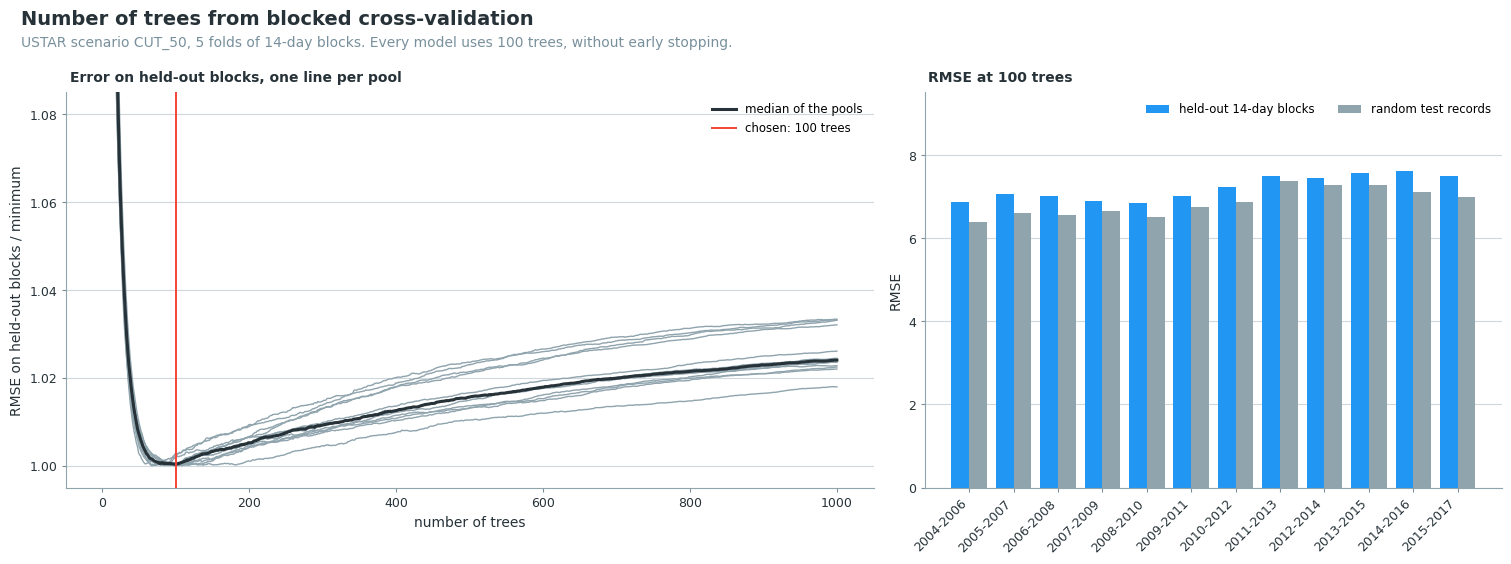

In [43]:
plot_tree_selection(data);

Next the scores on all measured records. The gaps are filled by a model refitted on all of them, so
these scores are better than the test scores and only show how closely the model fits.

### 📋 Table: scores on all measured records

In [44]:
report_gapfilling_model_scores(data)

In-sample scores
method    USTAR    year      R²   RMSE    MAE   MedAE   MaxE
────────────────────────────────────────────────────────────
MDS       CUT_16   all    0.487   7.65   5.05    3.18   78.8
MDS       CUT_50   all    0.500   7.63   5.06    3.19   78.8
MDS       CUT_84   all    0.510   7.64   5.07    3.22   78.8
XGBoost   CUT_16   2004   0.677   5.44   3.69    2.41   38.6
XGBoost   CUT_16   2005   0.677   5.44   3.69    2.41   38.6
XGBoost   CUT_16   2006   0.672   5.70   3.82    2.45   48.2
XGBoost   CUT_16   2007   0.687   5.68   3.80    2.44   46.5
XGBoost   CUT_16   2008   0.704   5.71   3.82    2.45   49.4
XGBoost   CUT_16   2009   0.715   5.60   3.77    2.45   41.8
XGBoost   CUT_16   2010   0.717   5.73   3.88    2.54   39.9
XGBoost   CUT_16   2011   0.711   5.87   3.99    2.62   40.3
XGBoost   CUT_16   2012   0.704   6.14   4.16    2.70   48.0
XGBoost   CUT_16   2013   0.699   6.13   4.16    2.68   52.7
XGBoost   CUT_16   2014   0.687   6.21   4.21    2.72   51.4
XGBoost   CUT_16   2015   0.698   6.22   4.23    2.76   47.0
XGBoost   CUT_16   2016   0.710   6.01   4.09    2.66   43.4
XGBoost   CUT_16   2017   0.710   6.01   4.09    2.66   43.4
XGBoost   CUT_16   mean   0.698   5.85   3.96    2.57   44.9
                                                            
XGBoost   CUT_50   2004   0.685   5.43   3.68    2.41   37.2
XGBoost   CUT_50   2005   0.685   5.43   3.68    2.41   37.2
XGBoost   CUT_50   2006   0.685   5.64   3.78    2.45   49.5
XGBoost   CUT_50   2007   0.697   5.64   3.77    2.43   51.0
XGBoost   CUT_50   2008   0.716   5.65   3.79    2.46   50.4
XGBoost   CUT_50   2009   0.729   5.53   3.74    2.44   40.7
XGBoost   CUT_50   2010   0.725   5.72   3.88    2.55   40.6
XGBoost   CUT_50   2011   0.723   5.79   3.94    2.61   37.3
XGBoost   CUT_50   2012   0.718   6.05   4.11    2.68   38.7
XGBoost   CUT_50   2013   0.706   6.10   4.14    2.66   41.9
XGBoost   CUT_50   2014   0.696   6.17   4.19    2.71   44.0
XGBoost   CUT_50   2015   0.709   6.15   4.19    2.76   40.8
XGBoost   CUT_50   2016   0.723   5.95   4.07    2.68   45.6
XGBoost   CUT_50   2017   0.723   5.95   4.07    2.68   45.6
XGBoost   CUT_50   mean   0.709   5.80   3.93    2.57   42.9
                                                            
XGBoost   CUT_84   2004   0.700   5.37   3.64    2.41   39.8
XGBoost   CUT_84   2005   0.700   5.37   3.64    2.41   39.8
XGBoost   CUT_84   2006   0.699   5.60   3.76    2.44   44.0
XGBoost   CUT_84   2007   0.711   5.59   3.74    2.44   50.2
XGBoost   CUT_84   2008   0.729   5.58   3.76    2.45   44.4
XGBoost   CUT_84   2009   0.737   5.50   3.73    2.44   41.5
XGBoost   CUT_84   2010   0.741   5.59   3.82    2.55   41.0
XGBoost   CUT_84   2011   0.732   5.76   3.92    2.59   38.0
XGBoost   CUT_84   2012   0.726   6.02   4.11    2.69   41.2
XGBoost   CUT_84   2013   0.719   6.04   4.12    2.69   42.1
XGBoost   CUT_84   2014   0.710   6.10   4.17    2.72   42.9
XGBoost   CUT_84   2015   0.719   6.12   4.19    2.76   39.3
XGBoost   CUT_84   2016   0.732   5.90   4.06    2.70   39.3
XGBoost   CUT_84   2017   0.732   5.90   4.06    2.70   39.3
XGBoost   CUT_84   mean   0.721   5.74   3.91    2.57   41.6
Model predictions against every measured record, training records included, so optimistic for the ML
methods.
MDS predicts each measured record without using it, so its scores are out-of-sample and not 
comparable with those of the ML methods; report_gapfilling_comparison scores both on the same 
held-out records.
Errors are in the units of the flux.

### 📋 Table: years used to train each year's model

In [45]:
report_gapfilling_poolyears(data)

Years pooled for each year's model
model year   trained on, all ML runs
────────────────────────────────────
2004         2004-2006              
2005         2004-2006              
2006         2005-2007              
2007         2006-2008              
2008         2007-2009              
2009         2008-2010              
2010         2009-2011              
2011         2010-2012              
2012         2011-2013              
2013         2012-2014              
2014         2013-2015              
2015         2014-2016              
2016         2015-2017              
2017         2015-2017              
Not available for MDS (CUT_16), MDS (CUT_50), MDS (CUT_84) (does not pool years).

### 📋 Table: most important features (SHAP), CUT_16

In [46]:
report_gapfilling_feature_importances(data, ustar_scenario='CUT_16')

Feature importances, XGBoost (CUT_16): top 10 of 87 features, mean |SHAP|
 #   feature                            2004   2005   2006   2007   2008   2009   2010   2011   2012   2013   2014   2015   2016   2017   mean
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 1   .DOY_COS                           1.68   1.68   1.35   2.00   1.77   1.01   1.34   1.07   2.11   2.21   2.14   2.18   2.14   2.14   1.77
 2   .SW_IN_T1_47_1_gfXG_ROLLMAX2       0.87   0.87   0.85   1.10   1.85   1.50   1.08   0.62   1.05   1.18   2.01   1.97   1.40   1.40   1.27
 3   .SW_IN_T1_47_1_gfXG_ROLLMAX4       1.43   1.43   1.59   0.67   1.33   1.56   2.31   1.67   1.68   1.09   0.43   0.43   0.44   0.44   1.18
 4   .SW_IN_T1_47_1_gfXG_ROLLMIN4       1.07   1.07   0.75   0.85   0.90   0.71   0.66   0.81   0.99   0.76   1.36   1.29   1.32   1.32   0.99
 5   .HOUR_COS                          0.85   0.85   0.89   0.79   0.82   0.80   0.75   0.87   0.82   0.87   0.84   0.96   0.98   0.98   0.86
 6   SW_IN_T1_47_1_gfXG                 0.51   0.51   0.49   0.86   0.96   0.31   0.07   0.07   0.11   0.40   0.85   0.69   0.95   0.95   0.55
 7   .WEEK_COS                          0.58   0.58   0.90   0.06   0.16   0.74   0.49   1.06   0.16   0.03   0.12   0.25   0.35   0.35   0.42
 8   .DOY_SIN                           0.52   0.52   0.43   0.38   0.17   0.11   0.15   0.23   0.34   0.55   0.47   0.36   0.43   0.43   0.36
 9   .SW_IN_T1_47_1_gfXG_ROLLMEDIAN12   0.43   0.43   0.38   0.34   0.38   0.32   0.58   0.41   0.37   0.34   0.15   0.22   0.28   0.28   0.35
10   .MONTH_SIN                         0.21   0.21   0.13   0.18   0.49   0.70   0.77   0.66   0.55   0.18   0.18   0.21   0.22   0.22   0.35

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_16) (no model trained).

### 📋 Table: most important features (SHAP), CUT_50

In [47]:
report_gapfilling_feature_importances(data, ustar_scenario='CUT_50')

Feature importances, XGBoost (CUT_50): top 10 of 87 features, mean |SHAP|
 #   feature                        2004   2005   2006   2007   2008   2009   2010   2011   2012   2013   2014   2015   2016   2017   mean
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 1   .DOY_COS                       1.66   1.66   1.35   2.07   1.91   0.95   1.26   1.18   2.07   2.37   2.30   2.20   2.29   2.29   1.83
 2   .SW_IN_T1_47_1_gfXG_ROLLMAX2   0.66   0.66   0.74   1.14   1.56   1.34   0.80   0.89   0.96   1.22   2.22   1.82   1.41   1.41   1.20
 3   .SW_IN_T1_47_1_gfXG_ROLLMAX4   1.43   1.43   1.84   0.91   1.38   1.66   2.48   1.63   1.59   1.28   0.38   0.11   0.21   0.21   1.18
 4   .SW_IN_T1_47_1_gfXG_ROLLMIN4   0.99   0.99   0.53   0.73   1.12   0.61   0.75   0.88   0.93   0.65   1.15   1.19   1.31   1.31   0.94
 5   .HOUR_COS                      0.86   0.86   0.86   0.75   0.89   0.68   0.71   0.86   0.63   0.88   0.79   0.95   0.96   0.96   0.83
 6   SW_IN_T1_47_1_gfXG             0.47   0.47   0.53   1.27   0.97   0.37   0.10   0.06   0.18   0.42   0.68   0.91   1.22   1.22   0.63
 7   .WEEK_COS                      0.59   0.59   1.09   0.06   0.19   0.88   0.59   0.95   0.17   0.04   0.07   0.30   0.31   0.31   0.44
 8   .SW_IN_T1_47_1_gfXG_MEAN4      0.01   0.01   0.11   0.48   0.16   0.68   0.31   0.02   0.23   0.38   0.28   0.59   1.18   1.18   0.40
 9   .DOY_SIN                       0.57   0.57   0.40   0.39   0.18   0.13   0.14   0.33   0.45   0.39   0.47   0.43   0.42   0.42   0.38
10   .MONTH_SIN                     0.27   0.27   0.07   0.09   0.44   0.71   0.82   0.67   0.48   0.23   0.18   0.21   0.21   0.21   0.35

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_50) (no model trained).

### 📋 Table: most important features (SHAP), CUT_84

In [48]:
report_gapfilling_feature_importances(data, ustar_scenario='CUT_84')

Feature importances, XGBoost (CUT_84): top 10 of 87 features, mean |SHAP|
 #   feature                        2004   2005   2006   2007   2008   2009   2010   2011   2012   2013   2014   2015   2016   2017   mean
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 1   .DOY_COS                       1.79   1.79   1.32   2.15   2.01   0.80   1.15   0.98   2.17   2.35   2.40   2.43   2.34   2.34   1.86
 2   .SW_IN_T1_47_1_gfXG_ROLLMAX2   0.65   0.65   0.95   1.10   1.56   1.35   0.99   0.60   0.74   1.12   2.07   1.94   1.18   1.18   1.15
 3   .SW_IN_T1_47_1_gfXG_ROLLMAX4   1.29   1.29   1.71   0.71   1.15   1.47   2.22   1.62   2.14   1.37   0.21   0.04   0.18   0.18   1.11
 4   .SW_IN_T1_47_1_gfXG_ROLLMIN4   1.11   1.11   0.81   0.73   1.17   0.57   0.73   0.84   0.94   0.65   1.21   1.18   1.24   1.24   0.97
 5   .HOUR_COS                      0.91   0.91   0.86   0.75   0.93   0.71   0.76   0.95   0.70   0.85   0.72   1.00   1.00   1.00   0.86
 6   SW_IN_T1_47_1_gfXG             0.47   0.47   0.61   1.23   1.07   0.26   0.08   0.06   0.14   0.29   0.72   0.83   1.26   1.26   0.63
 7   .SW_IN_T1_47_1_gfXG_MEAN2      0.71   0.71   0.17   0.04   0.30   0.79   0.38   0.15   0.34   0.44   0.56   1.13   1.08   1.08   0.56
 8   .WEEK_COS                      0.61   0.61   1.27   0.07   0.21   1.01   0.66   1.09   0.04   0.02   0.08   0.22   0.37   0.37   0.47
 9   .DOY_SIN                       0.59   0.59   0.43   0.40   0.23   0.12   0.14   0.36   0.42   0.46   0.44   0.45   0.48   0.48   0.40
10   .MONTH_SIN                     0.22   0.22   0.05   0.10   0.40   0.67   0.86   0.74   0.60   0.21   0.23   0.21   0.17   0.17   0.35

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_84) (no model trained).

### 📊 Plot: feature ranks per year

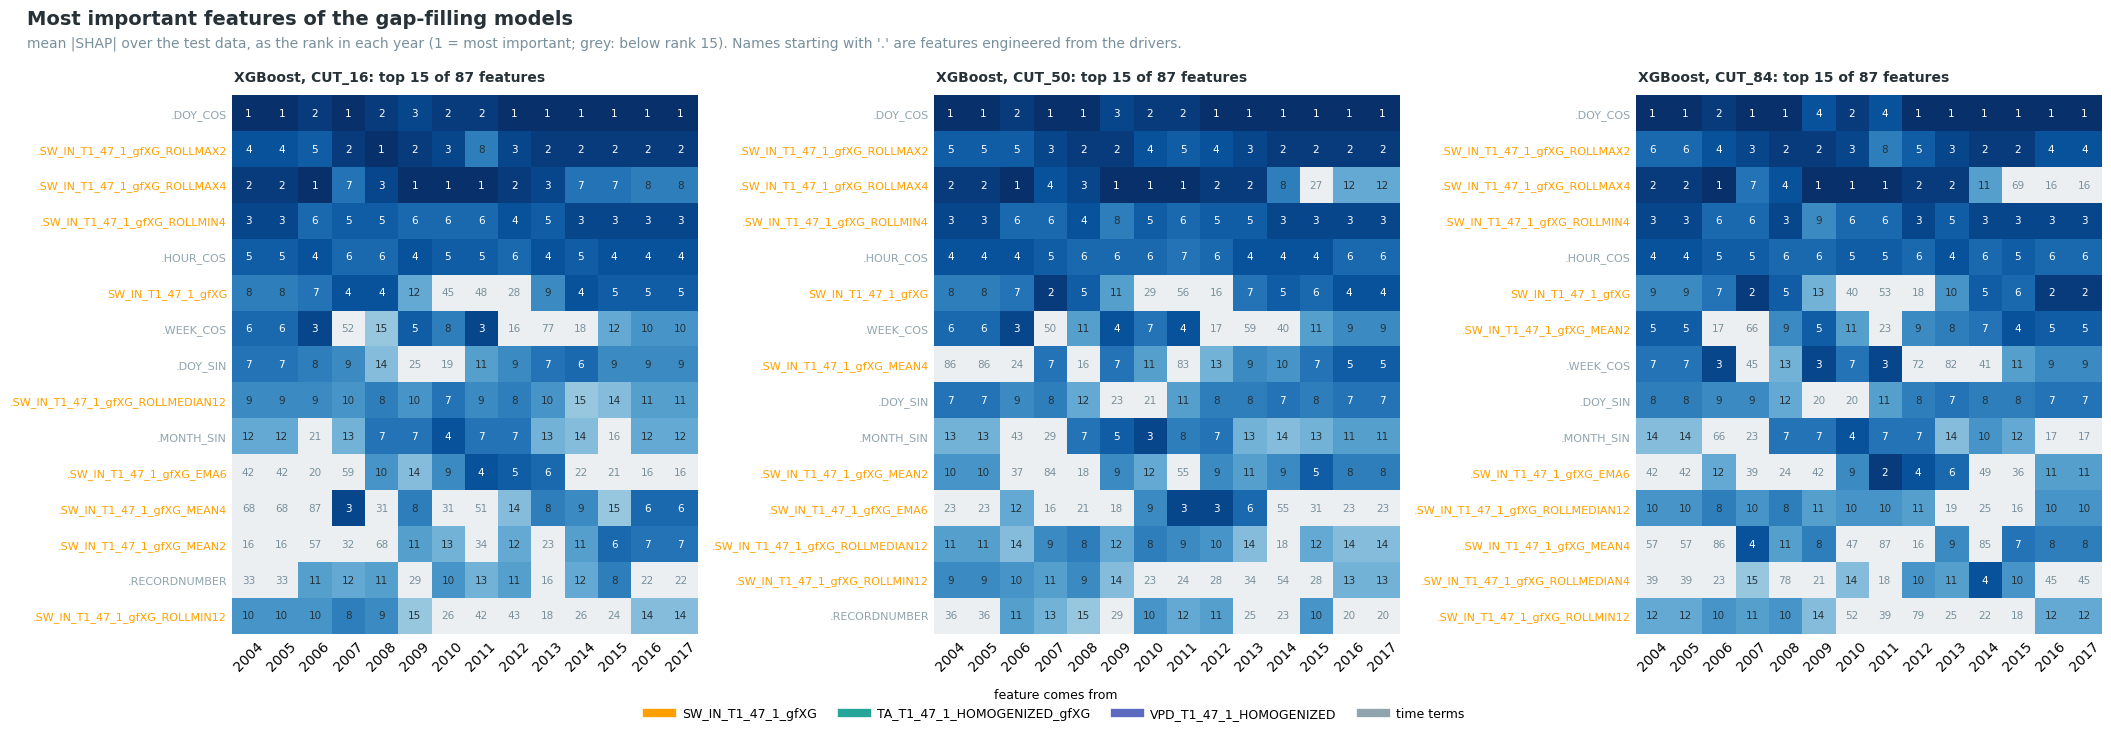

In [49]:
plot_feature_ranks_per_year(data)

## Step 11: result plots

### 📊 Plot: flux by quality class, heatmaps, XGBoost, CUT_50

The highest-quality records (QCF 0), the records the gap-filling used (QCF 0 and 1), the rejected
records, and the gap-filled result, on one colour scale.

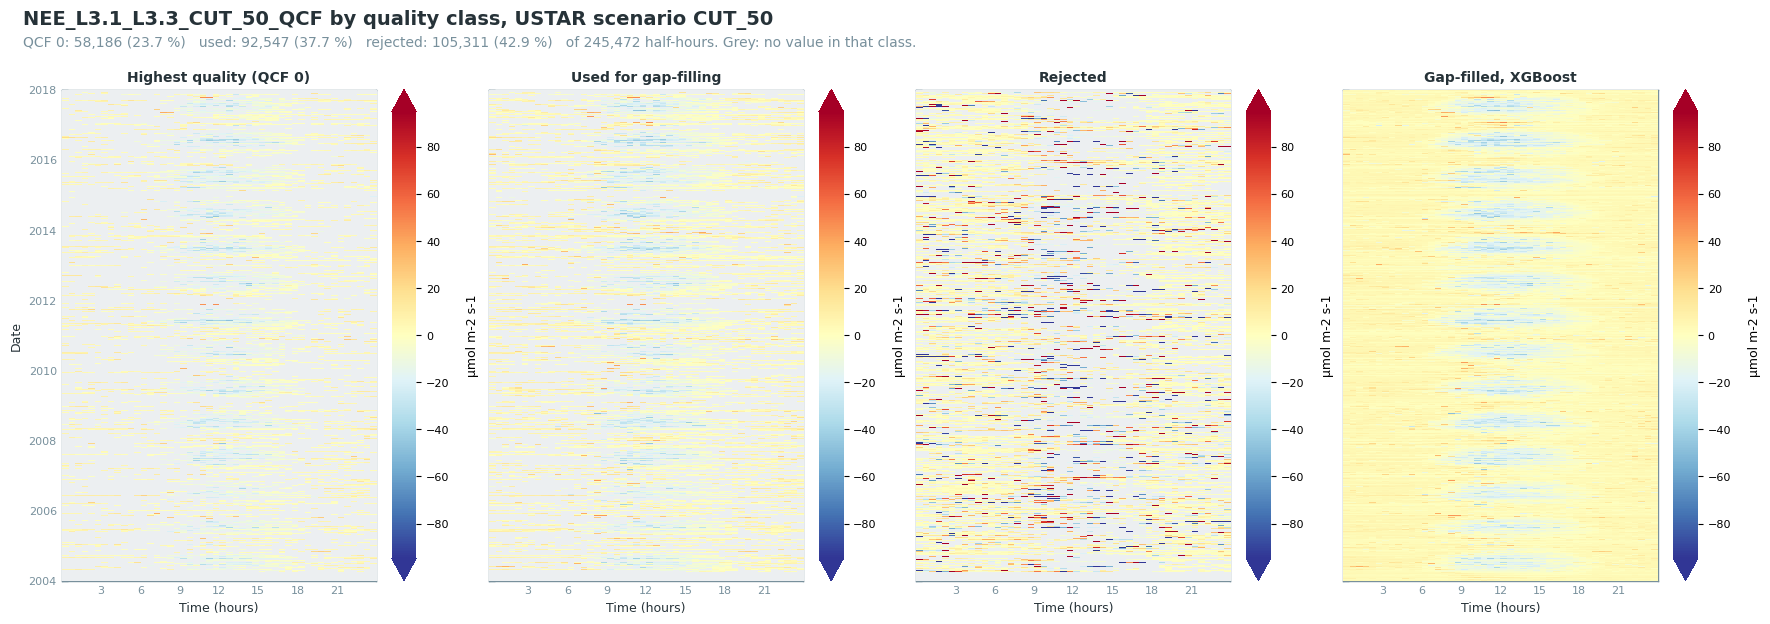

In [50]:
plot_quality_heatmaps(data, ustar_scenario='CUT_50', units=FLUX_UNITS, method='xgb')

### 📊 Plot: flux by quality class, day and night, XGBoost, CUT_50

Daytime and nighttime records by quality class, then the gap-filled result, with measured and
filled records shown apart.

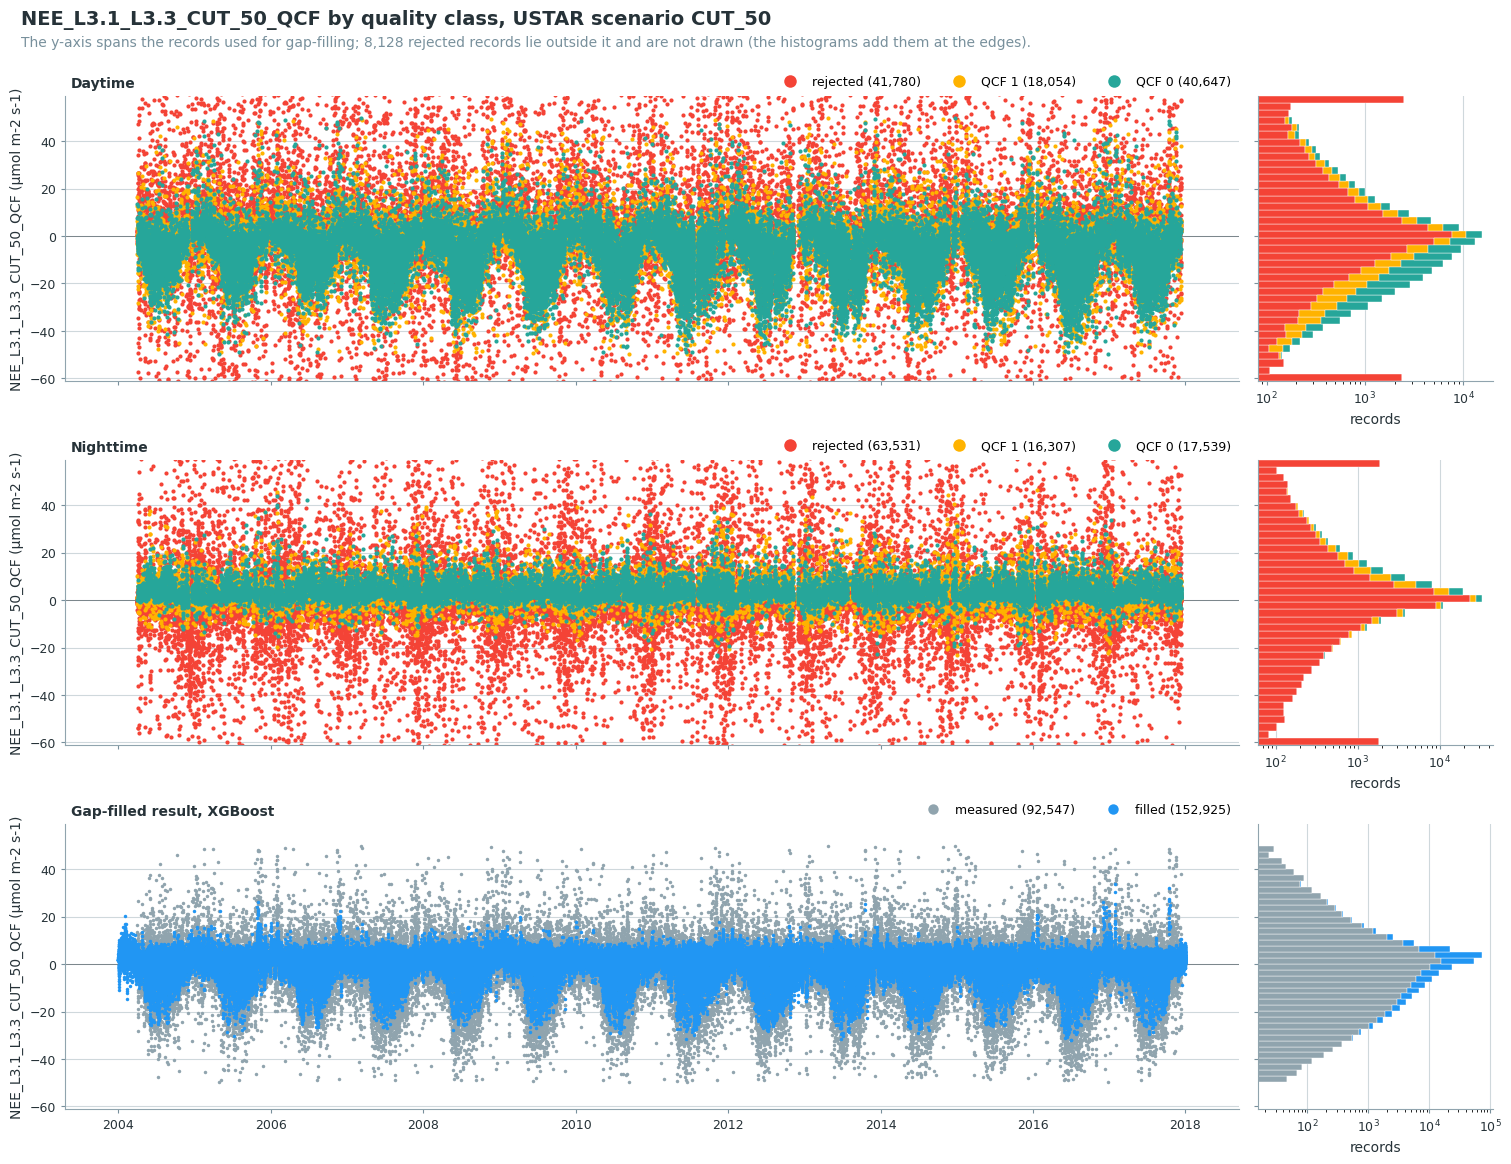

In [51]:
plot_quality_timeseries(data, ustar_scenario='CUT_50', units=FLUX_UNITS, method='xgb')

### 📊 Plot: measured and gap-filled flux, CUT_50

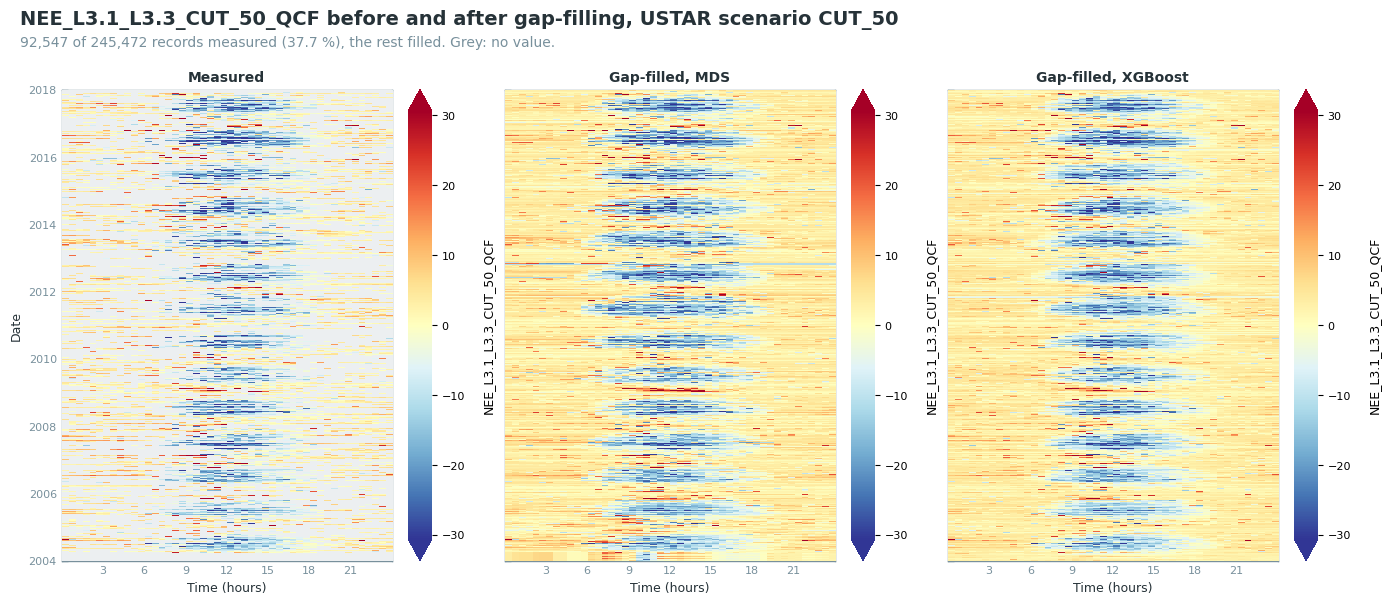

In [52]:
data.plot_gapfilled_heatmaps(ustar_scenario='CUT_50')

### 📊 Plot: cumulative flux, CUT_50

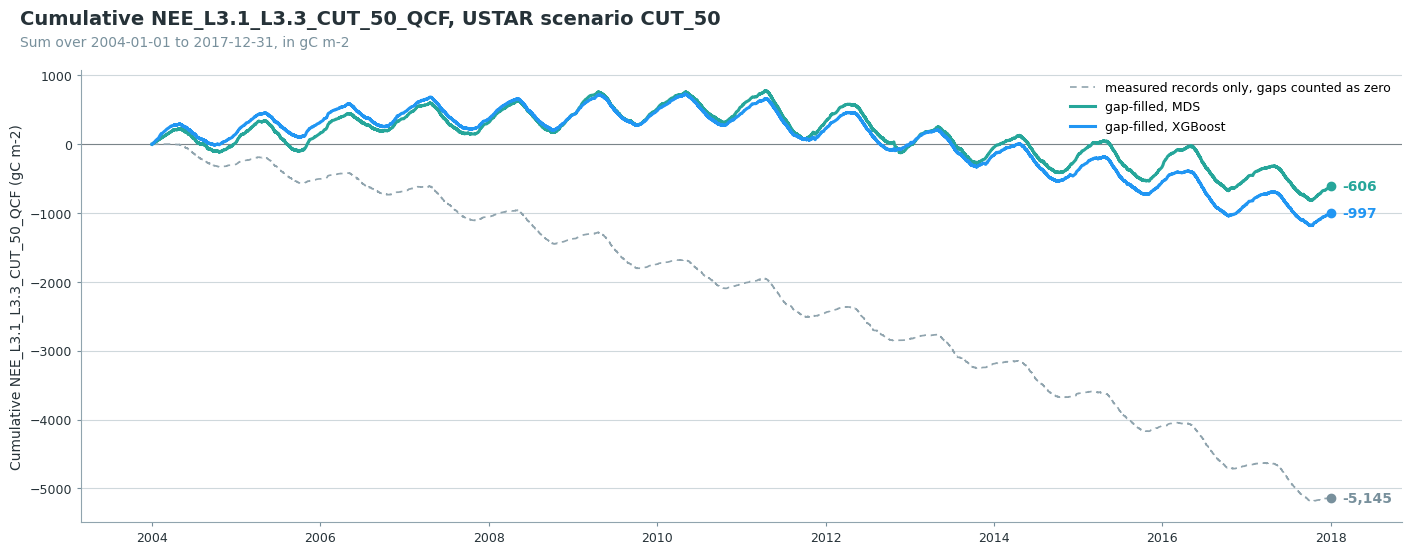

In [53]:
data.plot_cumulative_comparison(
    ustar_scenario='CUT_50',
    conv_factor=UMOL_TO_GC,
    units='gC m-2',
)

### 📊 Plot: cumulative flux of all USTAR scenarios

One line per gap-filling method and USTAR scenario, each method in its own colour. The spread
between CUT_16, CUT_50 and CUT_84 shows how much the annual sum depends on the USTAR threshold. It also contains the variation of the gap-filling model, which
changes with the records each scenario keeps.

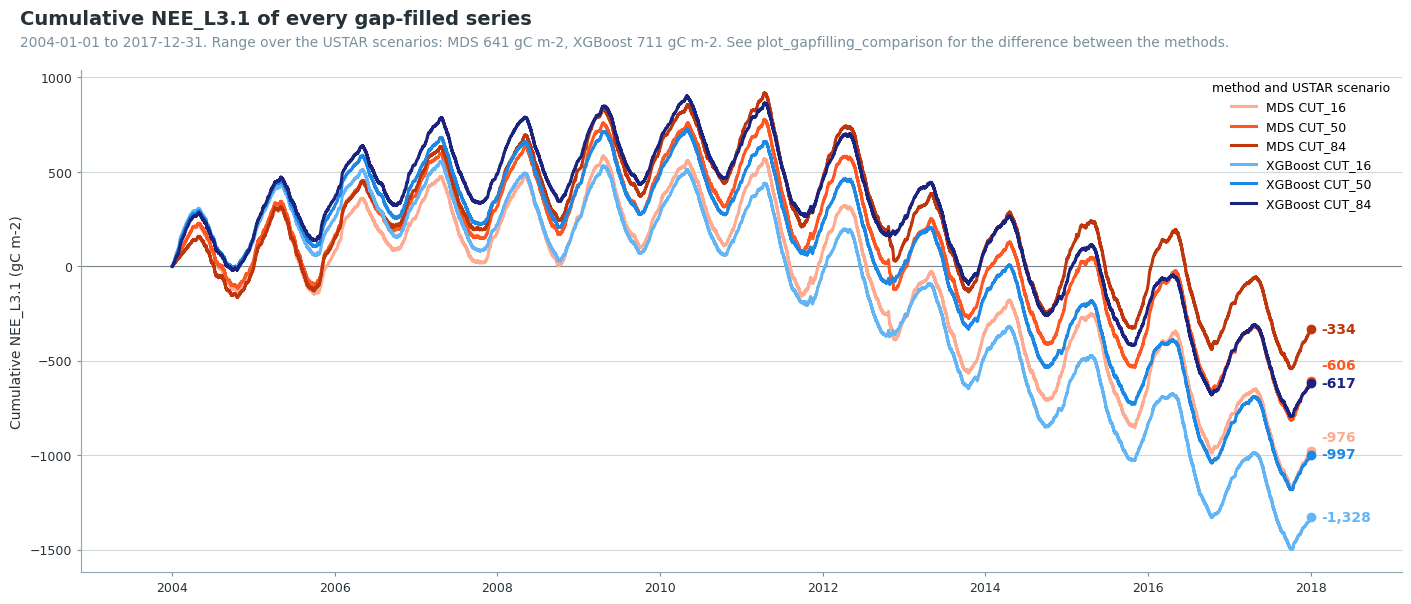

In [54]:
plot_gapfilled_cumulative(
    data,
    gain=UMOL_TO_GC,
    units='gC m-2',
    per_year=False,
)

### 📊 Plot: cumulative flux per year, for each scenario

One line per year; the band is the mean ± 1 SD of the full years. An incomplete last year is left
out of the band.

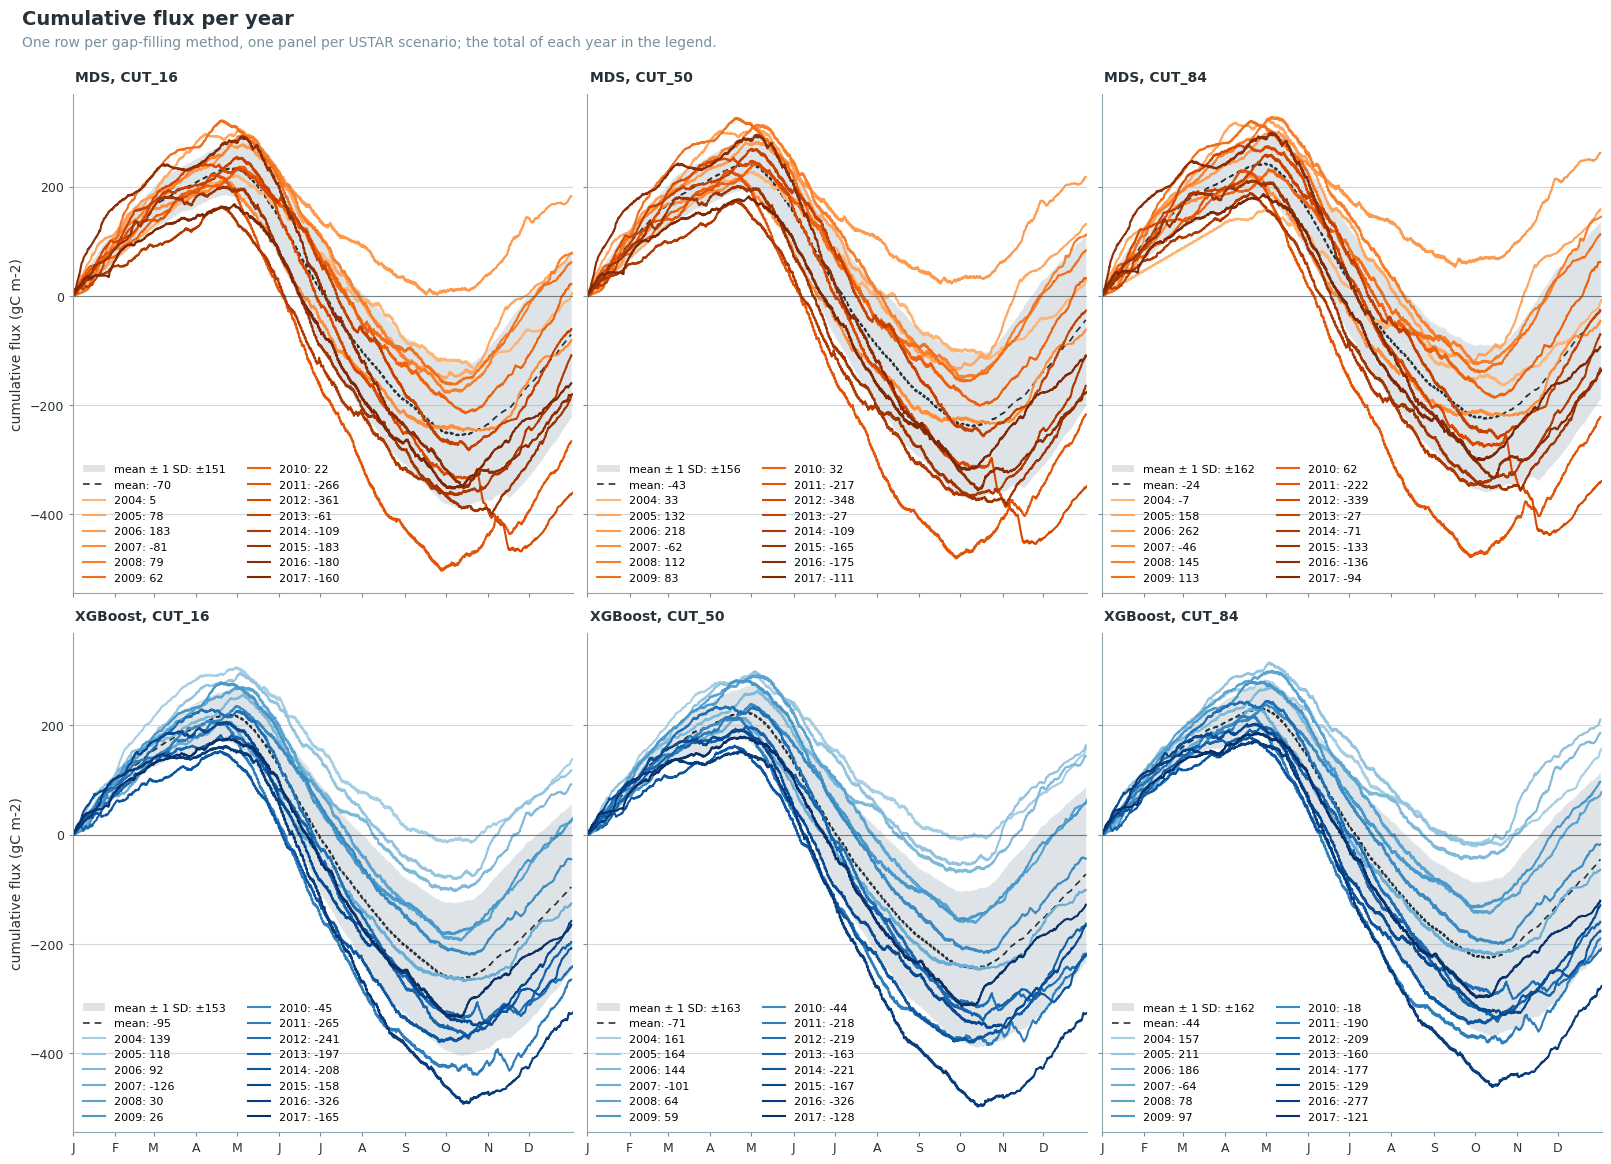

In [55]:
# One row per gap-filling method, one panel per USTAR scenario, on a shared y-axis. Years run
# from light to dark, so the most recent year is the darkest line.
_gf = data.gapfilled_cols()
_names = {'mds': 'MDS', 'xgb': 'XGBoost', 'rf': 'random forest'}
_months = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
# A last year that ends before 31 December stays out of the mean and the band.
_end = data.fpc_df.index[-1]
_partial = [_end.year] if (_end.month, _end.day) != (12, 31) else None
fig, axes = plt.subplots(len(_gf), len(USTAR_SCENARIOS), figsize=(16, 5.5 * len(_gf) + 0.6),
                         sharex=True, sharey=True, layout='constrained', squeeze=False)
for _row, (_method, _cols) in zip(axes, _gf.items()):
    for _ax, _scen in zip(_row, USTAR_SCENARIOS):
        _cum = doy_cumulatives_per_year(data.fpc_df[_cols[_scen]] * UMOL_TO_GC)
        _cum = _cum.loc[:, _cum.notna().any()]
        _years = list(_cum.columns)
        _shades = plt.get_cmap(cp.METHOD_CMAPS.get(_method, 'Greys'))(
            np.linspace(0.35, 1.0, len(_years)) if len(_years) > 1 else [0.85])
        if len(_years) > 1:
            _ref = doy_mean_cumulative(cumulatives_per_year_df=_cum,
                                       excl_years_from_reference=_partial)
            # Day 366 exists only in leap years, so the band stops before it.
            _ref = _ref.loc[_ref.index < 366]
            # The legend gives the mean and SD of the annual totals of the full years.
            _totals = [_cum[_y].dropna().iloc[-1] for _y in _years if _y not in (_partial or [])]
            _end_mean, _end_sd = np.mean(_totals), np.std(_totals, ddof=1)
            _ax.fill_between(_ref.index, _ref['MEAN-SD'], _ref['MEAN+SD'], color=cp.KEPT,
                             alpha=0.3, linewidth=0, label=f'mean ± 1 SD: ±{_end_sd:,.0f}')
            _ax.plot(_ref.index, _ref['MEAN_DOY_TIME'], color=cp.INK, linewidth=1.2,
                     linestyle=(0, (4, 3)), label=f'mean: {_end_mean:,.0f}')
        for _shade, _year in zip(_shades, _years):
            _valid = _cum[_year].dropna()
            _ax.plot(_cum.index, _cum[_year], color=_shade, linewidth=1.5,
                     label=f"{_year}: {_valid.iloc[-1]:,.0f}")
        _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
        cp.style_axes(_ax)
        cp.panel_label(_ax, f"{_names.get(_method, _method)}, {_scen}")
        _ax.set_xticks(_months, ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
        _ax.set_xlim(1, 367)
        _ax.legend(frameon=False, fontsize=8, ncol=1 if len(_years) < 8 else 2)
    _row[0].set_ylabel('cumulative flux (gC m-2)')
_subtitle = ("One row per gap-filling method, one panel per USTAR scenario; the total of each "
             "year in the legend.")
if _partial:
    _subtitle += f" {_end.year} ends on {_end:%d %B} and is left out of the mean and the band."
cp.figure_title(fig, 'Cumulative flux per year', _subtitle)
plt.show()

### Gap-filling methods compared

The difference between the sums of MDS and XGBoost comes from the filled gaps alone; the table
splits it by day and night and by gap length ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#method-comparison)).

**Skipped** when `RUN_MDS = False`.

#### 📋 Table: MDS and XGBoost, sums and their difference

In [56]:
if RUN_MDS:
    report_gapfilling_comparison(data, methods=('mds', 'xgb'), gain=UMOL_TO_GC, units='gC m-2');

Gap-filling methods compared: MDS and XGBoost
          sum       sum                    from         from   gaps   gaps    gaps   gaps
USTAR     MDS   XGBoost   difference   day gaps   night gaps      1   2-12   13-48    >48
─────────────────────────────────────────────────────────────────────────────────────────
CUT_16   -976    -1,328         -352       -291          -61     32    220    -146   -458
CUT_50   -606      -997         -392       -223         -168     26    182     -71   -528
CUT_84   -334      -617         -283       -131         -152     20    170      38   -510
Sums (gC m-2). difference = XGBoost - MDS over the filled gaps, split into daytime and nighttime 
gaps and by gap length in records.
CUT_16, same 24,675 held-out records: MDS R² 0.50 RMSE 7.62, XGBoost R² 0.59 RMSE 6.84
CUT_50, same 23,073 held-out records: MDS R² 0.51 RMSE 7.62, XGBoost R² 0.60 RMSE 6.87
CUT_84, same 21,330 held-out records: MDS R² 0.52 RMSE 7.61, XGBoost R² 0.61 RMSE 6.86
Held-out records are random single half-hours, so these scores describe short gaps; the sums depend 
more on the long ones.

#### 📊 Plot: where MDS and XGBoost differ

The filled values of both methods at the same gaps, their mean difference by month and hour, the
contribution of each month to the difference of the sums, and the cumulative difference for every
USTAR scenario.

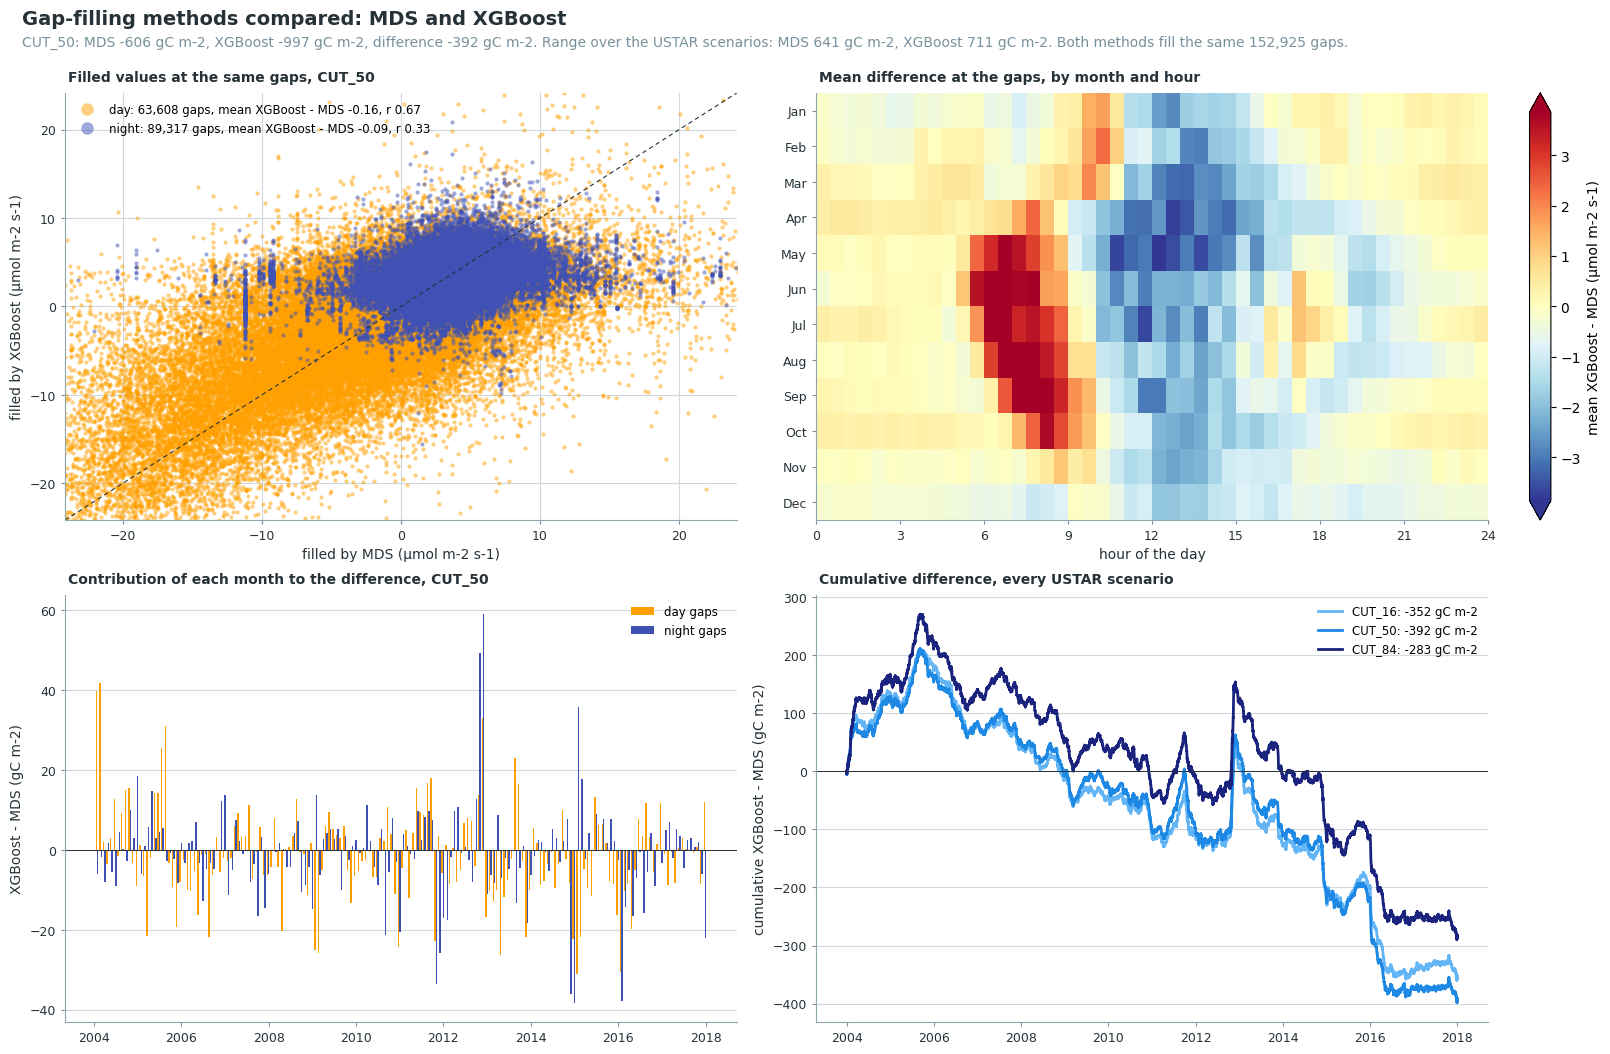

In [57]:
if RUN_MDS:
    plot_gapfilling_comparison(data, ustar_scenario='CUT_50', methods=('mds', 'xgb'),
                               gain=UMOL_TO_GC, units='gC m-2', flux_units=FLUX_UNITS);

## Step 12: uncertainty

Random, USTAR and joint uncertainty of the `UNC_REF` (CUT_50) series of each method, after
Pastorello et al. (2020), at 1 sigma in flux units. In sums the random part adds in quadrature and
the USTAR part as half the difference between the CUT_84 and CUT_16 sums; the difference between
the methods is reported beside them ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#uncertainty)).

### 📋 Table: random uncertainty, records per method

In [58]:
METHOD_NAMES = {'mds': 'MDS', 'xgb': 'XGBoost', 'rf': 'random forest'}
METHOD_COLORS = {_k: _v[1] for _k, _v in cp.METHOD_COLORS.items()}  # the hue of each method
GF_COLS = data.gapfilled_cols()  # {method: {USTAR scenario: gap-filled column}}
_m = data.merged_df(verbose=0)

RANDUNC = {}
for _method, _cols in GF_COLS.items():
    print(f"\n{METHOD_NAMES.get(_method, _method)}, {UNC_REF}")
    RANDUNC[_method] = dv.flux.RandomUncertaintyPAS20(
        df=_m,
        fluxcol=data.nongapfilled_cols()[_method][UNC_REF],
        fluxgapfilledcol=_cols[UNC_REF],
        tacol=TA_F,
        vpdcol=VPD_F,  # kPa
        swincol=SW_IN_F,
        vpd_in_kpa=True,
    )
    RANDUNC[_method].run()
    RANDUNC[_method].report_method_summary()


MDS, CUT_50


> Calculating random uncertainty with window size +/-7 days and +/-1 hours (method 1) ...

> Time needed: 6.23s

> Calculating random uncertainty with window size +/-14 days (method 2) ...

> Time needed: 11.37s

...

METHOD DISTRIBUTION:

Method  Records Percentage
1: Sliding Window (+/-7d, +/-1h) [ONEFlux]    51721      21.1%
 2: Similar Flux Median (+/-14d) [ONEFlux]   189208      77.1%
3: Similar Flux Median (no window)      4543       1.9%
                 4: Nearest Fluxes         0       0.0%

UNCERTAINTY STATISTICS (umol CO2 m-2 s-1):

Statistic Value (umol CO2 m-2 s-1)
     Mean                   4.4384
  Std Dev                   2.0516
      Min                   0.3053
      Max                  31.7934
    Range                  31.4881

================================================================================

### 📋 Table: random, USTAR and joint uncertainty per record

In [59]:
# Per method, the three columns written to the output file. The USTAR term is stored as a
# magnitude: CUT_84 is not always above CUT_16, and the joint uncertainty uses its square.
UNC = {}
for _method, _cols in GF_COLS.items():
    _gf = _cols[UNC_REF]
    _joint = dv.flux.JointUncertaintyPAS20(
        df=pd.DataFrame({f'{_gf}_RANDUNC': RANDUNC[_method].randunc_series,
                         'lower': _m[_cols[UNC_LOWER]],
                         'upper': _m[_cols[UNC_UPPER]]}),
        randunccol=f'{_gf}_RANDUNC',
        scenario_lower_col='lower',
        scenario_upper_col='upper',
        name=f'{_gf}_JOINTUNC',
    )
    _joint.run()
    print(f"\n{METHOD_NAMES.get(_method, _method)}, {UNC_REF}")
    _joint.report_summary()
    _res = _joint.jointunc_results.rename(columns={_joint.scenarionunccol: f'{_gf}_USTARUNC'})
    _res[f'{_gf}_USTARUNC'] = _res[f'{_gf}_USTARUNC'].abs()
    UNC[_method] = _res[[f'{_gf}_RANDUNC', f'{_gf}_USTARUNC', f'{_gf}_JOINTUNC']]
    assert UNC[_method].notna().all().all(), f"a record of {_gf} has no uncertainty"
UNC_EXPORT = pd.concat(UNC.values(), axis=1)

# The flux and its uncertainty of each method in gC m-2 per half-hour, the input of the sums below.
UNC_FRAMES = {
    _method: pd.DataFrame({
        'flux': _m[_cols[UNC_REF]] * UMOL_TO_GC,
        'var': (UNC[_method][f'{_cols[UNC_REF]}_RANDUNC'] * UMOL_TO_GC) ** 2,
        'lower': _m[_cols[UNC_LOWER]] * UMOL_TO_GC,
        'upper': _m[_cols[UNC_UPPER]] * UMOL_TO_GC,
    })
    for _method, _cols in GF_COLS.items()
}


def period_sums(frame, freq):
    """Sums per period and their 1-sigma uncertainty: the random part in quadrature, the USTAR
    part as half the spread of the CUT_84 and CUT_16 sums."""
    s = frame.resample(freq).sum()
    out = pd.DataFrame({'sum': s['flux'], 'random': np.sqrt(s['var']),
                        'USTAR': ((s['upper'] - s['lower']) / 2).abs()})
    out['joint'] = np.sqrt(out['random'] ** 2 + out['USTAR'] ** 2)
    return out


MDS, CUT_50


================================================================================

JOINT UNCERTAINTY (PAS20) SUMMARY

================================================================================

Output column: NEE_L3.1_L3.3_CUT_50_QCF_gfMDS_JOINTUNC  |  records with estimate: 245,472

...

Output column: NEE_L3.1_L3.3_CUT_50_QCF_gfXG_JOINTUNC  |  records with estimate: 245,472

random term      mean: 4.4384  median: 3.9596

scenario term    mean: 0.0670  median: 0.0000

joint            mean: 4.5165  median: 4.0331

================================================================================

### 📋 Table: annual sums with their uncertainty

`random`, `USTAR` and `joint` are 1-sigma uncertainties of the annual sum of each method. The
second table gives the difference between the methods, which is reported beside the joint
uncertainty and not included in it. An incomplete last year covers only part of it.

In [60]:
ANNUAL_UNC = {_method: period_sums(_f, 'YS').rename(index=lambda _t: _t.year)
              for _method, _f in UNC_FRAMES.items()}
print(f"Annual sums of the {UNC_REF} series and their uncertainty (gC m-2, 1 sigma)")
display(pd.concat({METHOD_NAMES.get(_k, _k): _v for _k, _v in ANNUAL_UNC.items()},
                  names=['method', 'year']).round(1))

if len(ANNUAL_UNC) > 1:
    _names = [METHOD_NAMES.get(_k, _k) for _k in ANNUAL_UNC]
    _s = pd.DataFrame({_n: _v['sum'] for _n, _v in zip(_names, ANNUAL_UNC.values())})
    _diff = pd.DataFrame({f'{_b} - {_a}': _s[_b] - _s[_a]
                          for _i, _a in enumerate(_names) for _b in _names[_i + 1:]})
    _diff.index.name = 'year'
    print(f"\nDifference between the methods (gC m-2), not part of the joint uncertainty")
    display(_diff.round(1))

Annual sums of the CUT_50 series and their uncertainty (gC m-2, 1 sigma)


sum  random  USTAR  joint
method  year                             
MDS     2004   33.0    12.8    6.0   14.2
        2005  131.5    13.4   40.4   42.6
        2006  217.9    13.2   39.6   41.7
        2007  -62.0    14.3   17.7   22.8
        2008  111.9    13.7   33.1   35.8
        2009   83.1    13.3   25.7   28.9
        2010   32.1    12.9   20.2   24.0
        2011 -217.2    15.4   22.3   27.1
        2012 -348.4    14.7   10.9   18.3
        2013  -27.0    15.7   16.9   23.1
        2014 -109.5    15.9   19.3   25.0
        2015 -164.8    14.6   25.3   29.2
        2016 -175.5    15.5   22.0   26.9
        2017 -111.2    13.6   33.3   35.9
XGBoost 2004  160.6    12.0    9.0   15.0
        2005  163.6    12.9   46.5   48.3
        2006  143.8    13.1   46.9   48.7
        2007 -101.4    14.1   30.9   33.9
        2008   64.1    13.7   24.1   27.7
        2009   58.7    13.1   35.5   37.8
        2010  -44.0    12.7   13.6   18.6
        2011 -218.0    15.3   37.7   40.7
        2012 -219.1    14.2   16.3   21.7
        2013 -163.3    15.6   18.5   24.2
        2014 -220.5    15.5   15.7   22.1
        2015 -167.0    14.3   14.5   20.3
        2016 -326.5    15.3   24.4   28.8
        2017 -128.4    13.5   22.2   26.0


Difference between the methods (gC m-2), not part of the joint uncertainty


,XGBoost - MDS
year,
2004,127.6
2005,32.0
2006,-74.1
2007,-39.5
2008,-47.8
2009,-24.4
2010,-76.1
2011,-0.8
2012,129.3


### 📊 Plot: annual sums with their uncertainty

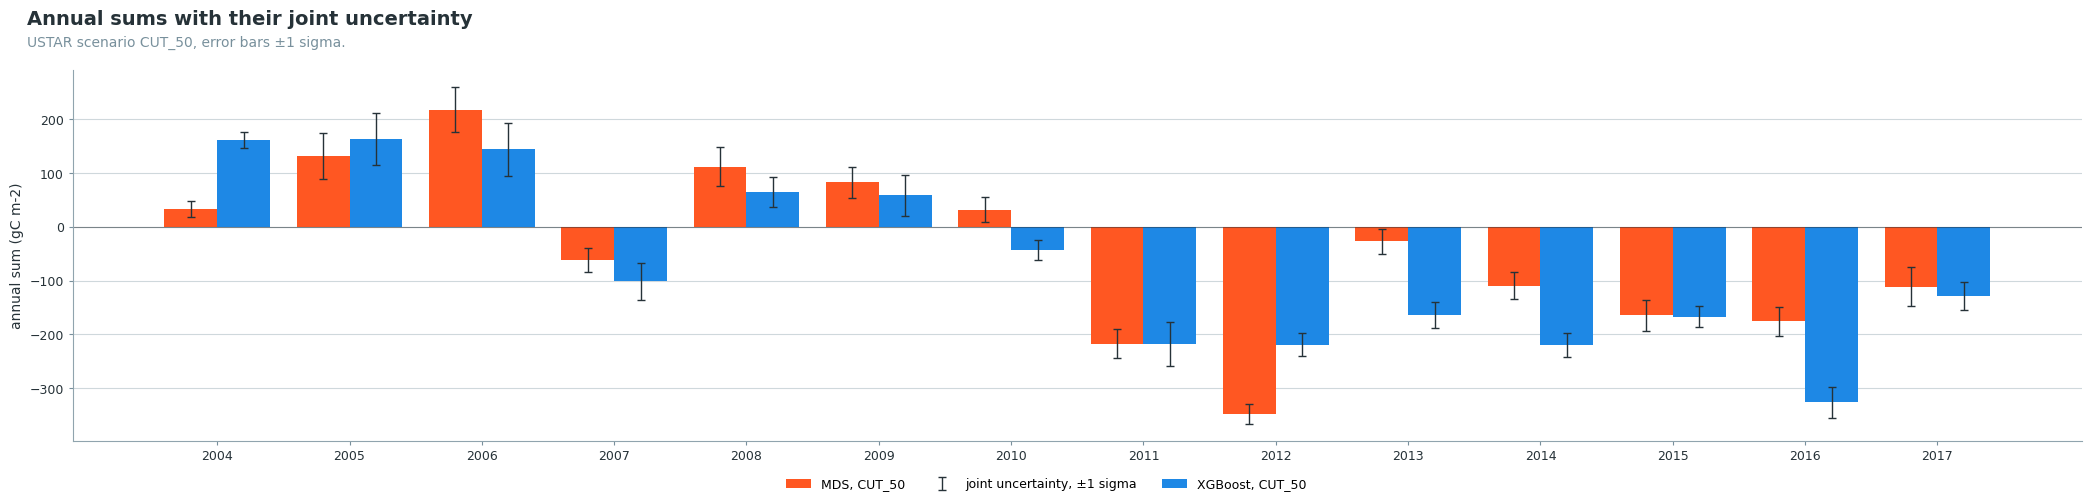

In [61]:
_methods = list(ANNUAL_UNC)
_years = ANNUAL_UNC[_methods[0]].index
_width = 0.8 / len(_methods)
_end = _m.index[-1]
fig, ax = plt.subplots(figsize=(max(8, 1.2 * len(_years) + 4), 5), layout='constrained')
for _i, _method in enumerate(_methods):
    _a = ANNUAL_UNC[_method]
    _x = np.arange(len(_years)) + (_i - (len(_methods) - 1) / 2) * _width
    ax.bar(_x, _a['sum'], _width, color=METHOD_COLORS.get(_method, cp.KEPT),
           label=f'{METHOD_NAMES.get(_method, _method)}, {UNC_REF}')
    ax.errorbar(_x, _a['sum'], yerr=_a['joint'], fmt='none', ecolor=cp.INK, capsize=3,
                linewidth=1, label='joint uncertainty, ±1 sigma' if _i == 0 else None)
ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
ax.set_xticks(np.arange(len(_years)), _years)
ax.set_ylabel('annual sum (gC m-2)')
cp.style_axes(ax)
fig.legend(*ax.get_legend_handles_labels(), loc='outside lower center', frameon=False,
           ncol=len(_methods) + 1, fontsize=9)
cp.figure_title(fig, 'Annual sums with their joint uncertainty',
                f"USTAR scenario {UNC_REF}, error bars ±1 sigma."
                + (f" {_end.year} ends on {_end:%d %B}." if (_end.month, _end.day) != (12, 31)
                   else ""))
plt.show()

### 📊 Plot: cumulative flux per year with its uncertainty

One panel per year, one line and band per gap-filling method. The band is the joint uncertainty,
accumulated from 1 January: the random part in quadrature, the USTAR part as half the spread of
the cumulative CUT_84 and CUT_16 sums. Where the bands of two methods do not overlap, the methods
differ by more than the joint uncertainty.

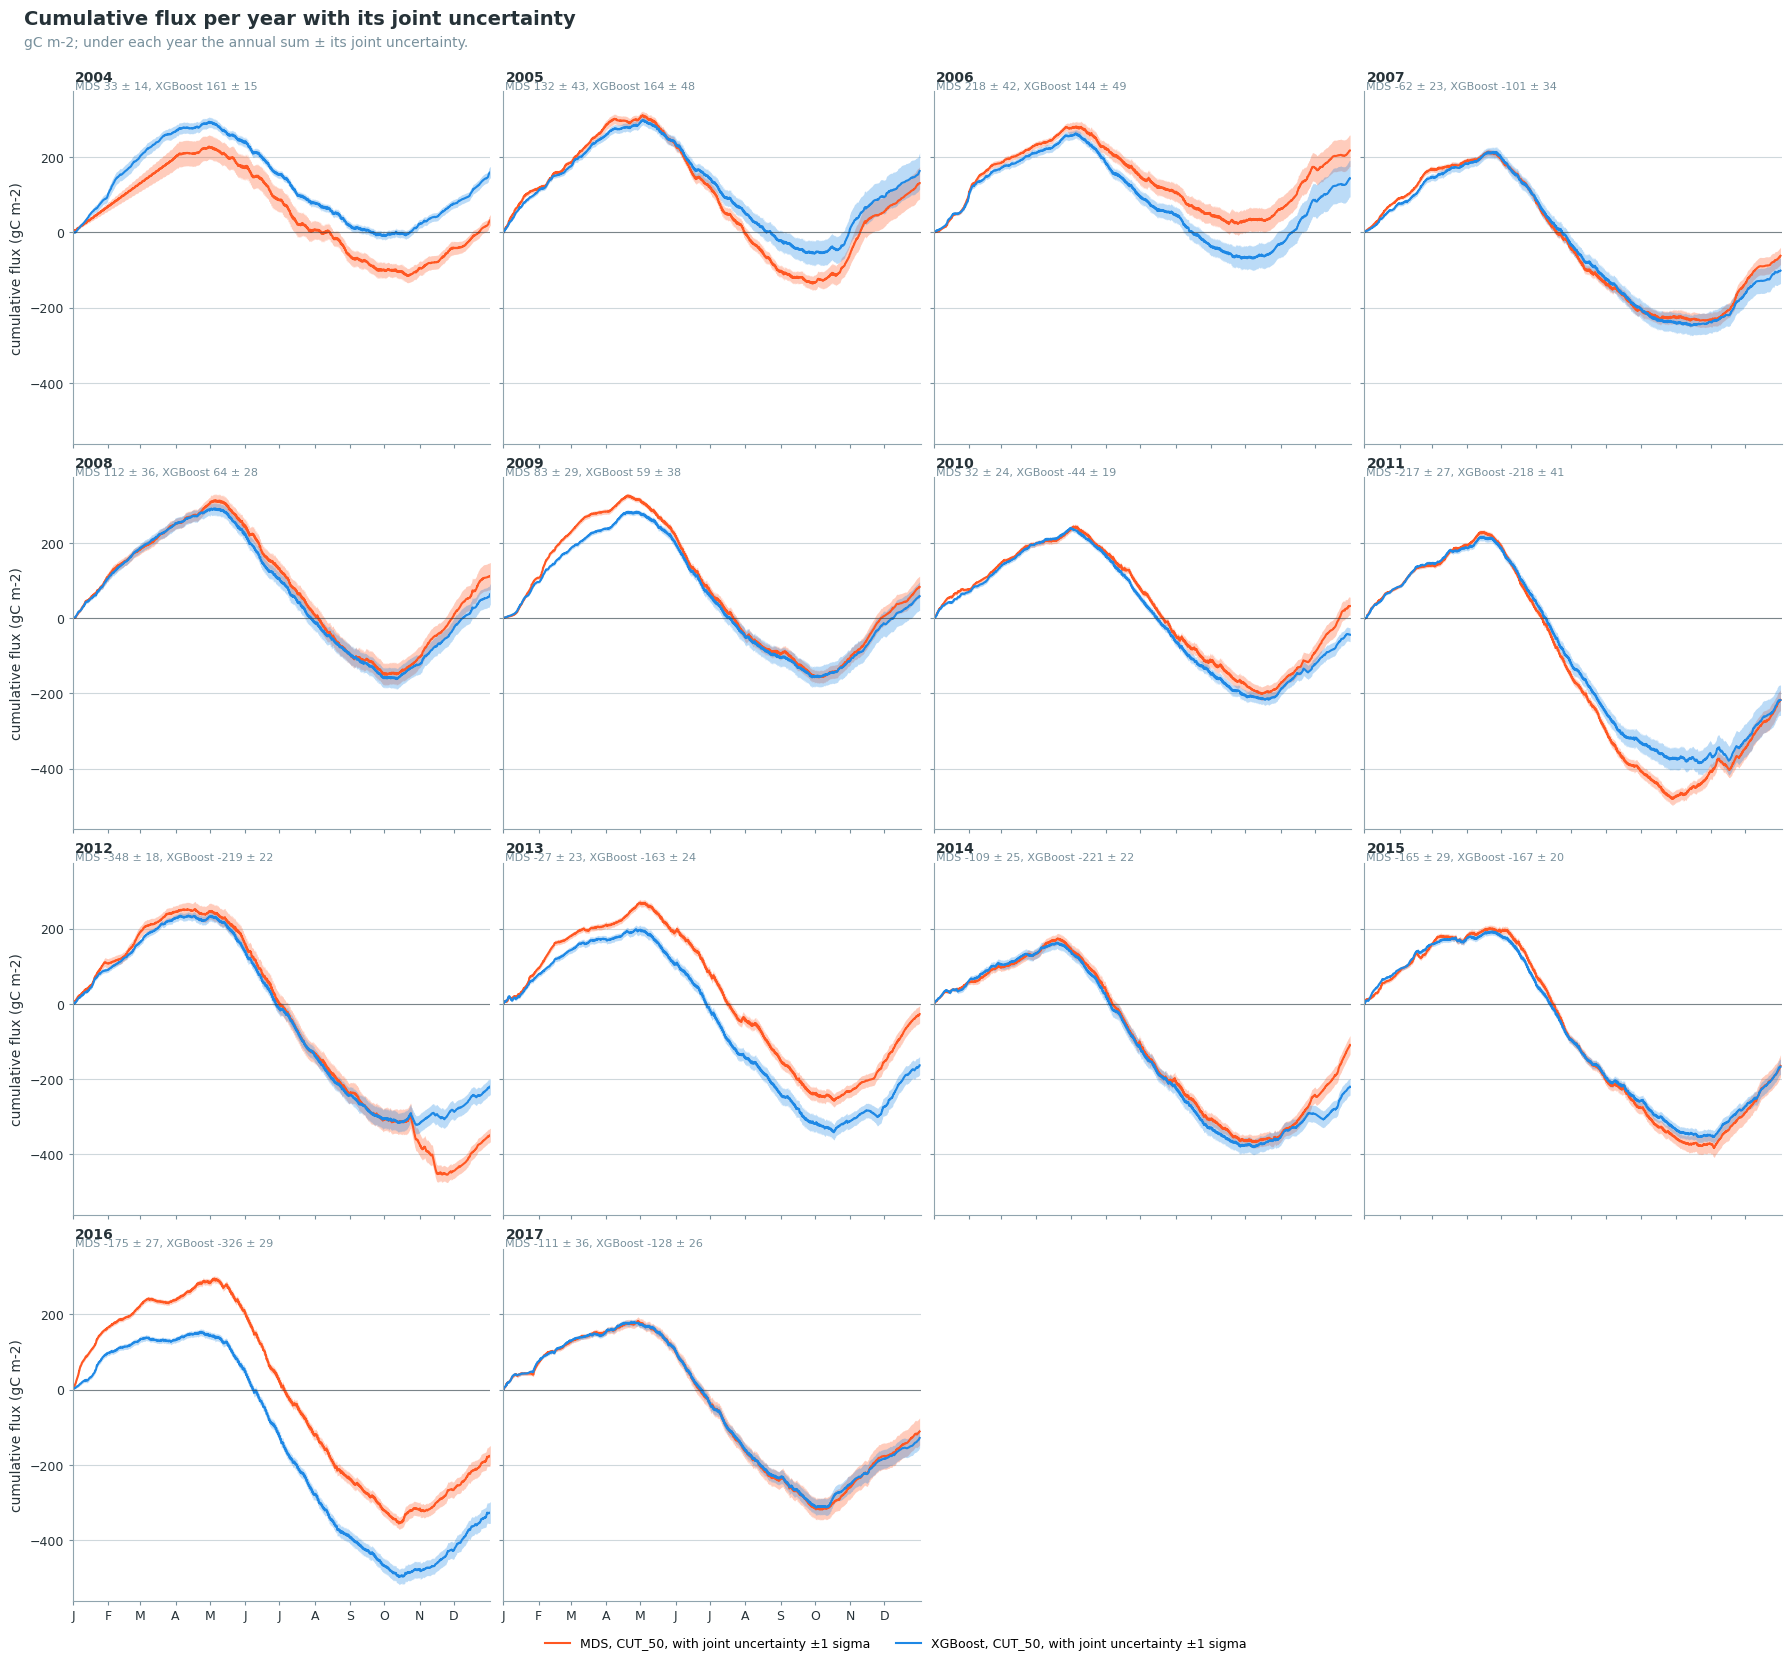

In [62]:
_years = sorted(set(_m.index.year))
_end = _m.index[-1]
_ncol = min(4, len(_years))
_nrow = -(-len(_years) // _ncol)
_month_starts = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
fig, axes = plt.subplots(_nrow, _ncol, figsize=(4.2 * _ncol + 1, 3.8 * _nrow + 1.4), sharex=True,
                         sharey=True, layout='constrained', squeeze=False)
for _ax, _year in zip(axes.flat, _years):
    _totals = []
    for _method, _f in UNC_FRAMES.items():
        _d = _f.loc[str(_year)]
        _doy = (_d.index.dayofyear + (_d.index.hour + _d.index.minute / 60) / 24).to_numpy()
        _cum = _d['flux'].cumsum()
        _joint = np.sqrt(_d['var'].cumsum()
                         + ((_d['upper'].cumsum() - _d['lower'].cumsum()) / 2) ** 2)
        _color = METHOD_COLORS.get(_method, cp.KEPT)
        _name = METHOD_NAMES.get(_method, _method)
        _ax.fill_between(_doy, _cum - _joint, _cum + _joint, color=_color, alpha=0.3,
                         linewidth=0)
        _ax.plot(_doy, _cum, color=_color, linewidth=1.5,
                 label=f'{_name}, {UNC_REF}, with joint uncertainty ±1 sigma')
        _totals.append(f"{_name} {_cum.iloc[-1]:,.0f} ± {_joint.iloc[-1]:,.0f}")
    _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    cp.style_axes(_ax)
    cp.panel_label(_ax, f"{_year}")
    _ax.text(0.005, 1.0, ", ".join(_totals), transform=_ax.transAxes, ha='left', va='bottom',
             fontsize=8, color=cp.MUTED)
    _ax.set_xticks(_month_starts, ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
    _ax.set_xlim(1, 367)
for _ax in axes.flat[len(_years):]:
    _ax.set_visible(False)
for _row in axes:
    _row[0].set_ylabel('cumulative flux (gC m-2)')
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc='outside lower center', frameon=False,
           ncol=len(UNC_FRAMES), fontsize=9)
cp.figure_title(fig, 'Cumulative flux per year with its joint uncertainty',
                "gC m-2; under each year the annual sum ± its joint uncertainty."
                + (f" {_end.year} ends on {_end:%d %B}." if (_end.month, _end.day) != (12, 31)
                   else ""))
plt.show()

### 📊 Plot: daily sums with their uncertainty

Two panels per gap-filling method: the daily sum with its joint uncertainty, then the uncertainty
of the daily sums and its two parts.

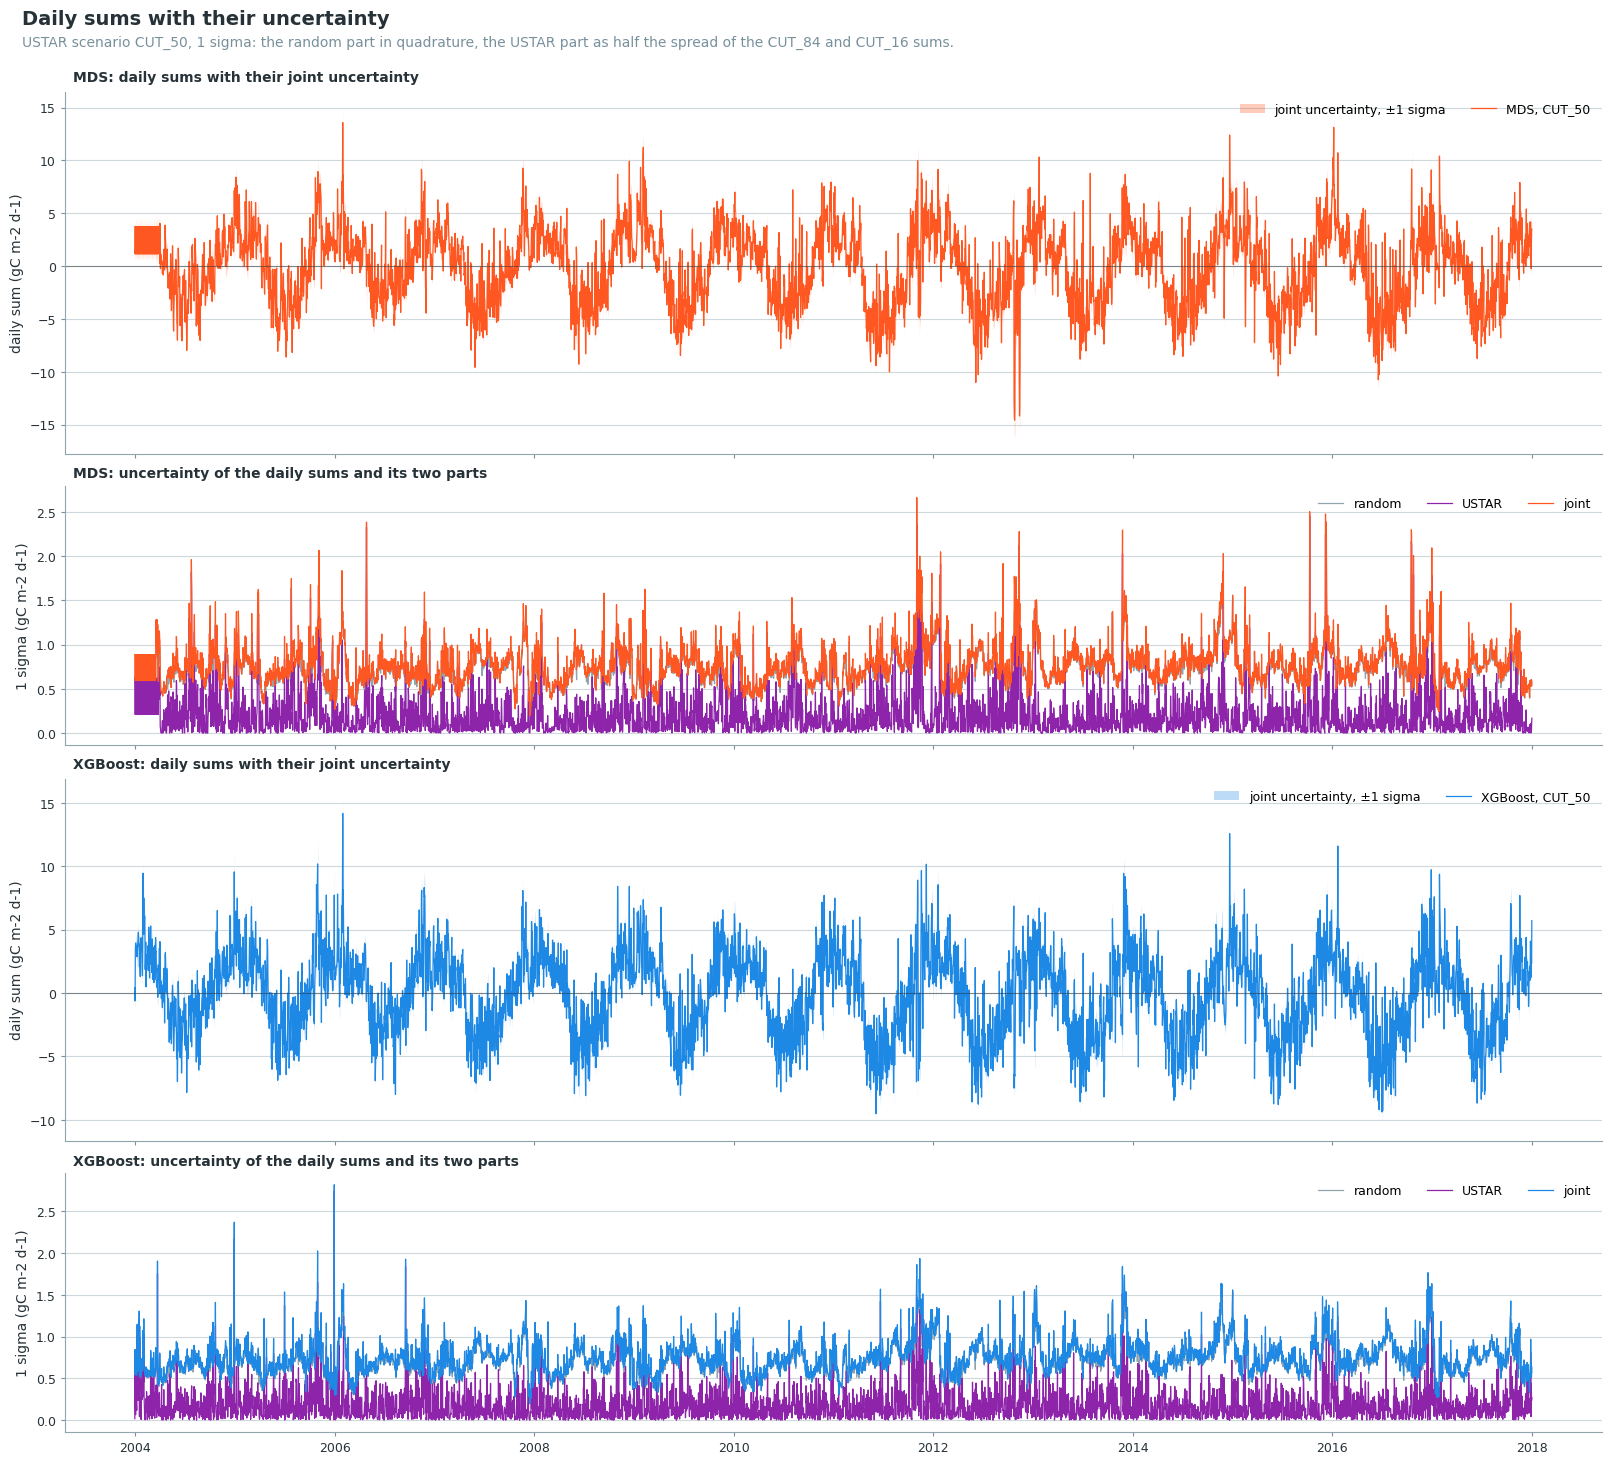

In [63]:
_methods = list(UNC_FRAMES)
fig, axs = plt.subplots(2 * len(_methods), 1, figsize=(16, 7 * len(_methods) + 0.6), sharex=True,
                        layout='constrained', height_ratios=[1.4, 1] * len(_methods))
for _i, _method in enumerate(_methods):
    _day = period_sums(UNC_FRAMES[_method], 'D')
    _color = METHOD_COLORS.get(_method, cp.KEPT)
    _name = METHOD_NAMES.get(_method, _method)
    _top, _bottom = axs[2 * _i], axs[2 * _i + 1]
    _top.fill_between(_day.index, _day['sum'] - _day['joint'], _day['sum'] + _day['joint'],
                      color=_color, alpha=0.3, linewidth=0, label='joint uncertainty, ±1 sigma')
    _top.plot(_day.index, _day['sum'], color=_color, linewidth=0.9, label=f'{_name}, {UNC_REF}')
    _top.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    _top.set_ylabel('daily sum (gC m-2 d-1)')
    cp.panel_label(_top, f'{_name}: daily sums with their joint uncertainty')
    for _col, _c in (('random', cp.KEPT), ('USTAR', cp.TEST_COLORS[2]), ('joint', _color)):
        _bottom.plot(_day.index, _day[_col], color=_c, linewidth=0.9, label=_col)
    _bottom.set_ylabel('1 sigma (gC m-2 d-1)')
    cp.panel_label(_bottom, f'{_name}: uncertainty of the daily sums and its two parts')
for _ax in axs:
    cp.style_axes(_ax)
    _ax.legend(frameon=False, fontsize=9, loc='upper right', ncol=3)
cp.figure_title(fig, 'Daily sums with their uncertainty',
                f"USTAR scenario {UNC_REF}, 1 sigma: the random part in quadrature, the USTAR part "
                f"as half the spread of the {UNC_UPPER} and {UNC_LOWER} sums.")
plt.show()

### 📊 Plot: heatmaps of the flux and its uncertainty

One row per gap-filling method, date against time of day. The random uncertainty grows with the
size of the flux. The USTAR uncertainty is zero where all three scenarios keep the measured
record, and appears only where a record was removed in one scenario and filled.

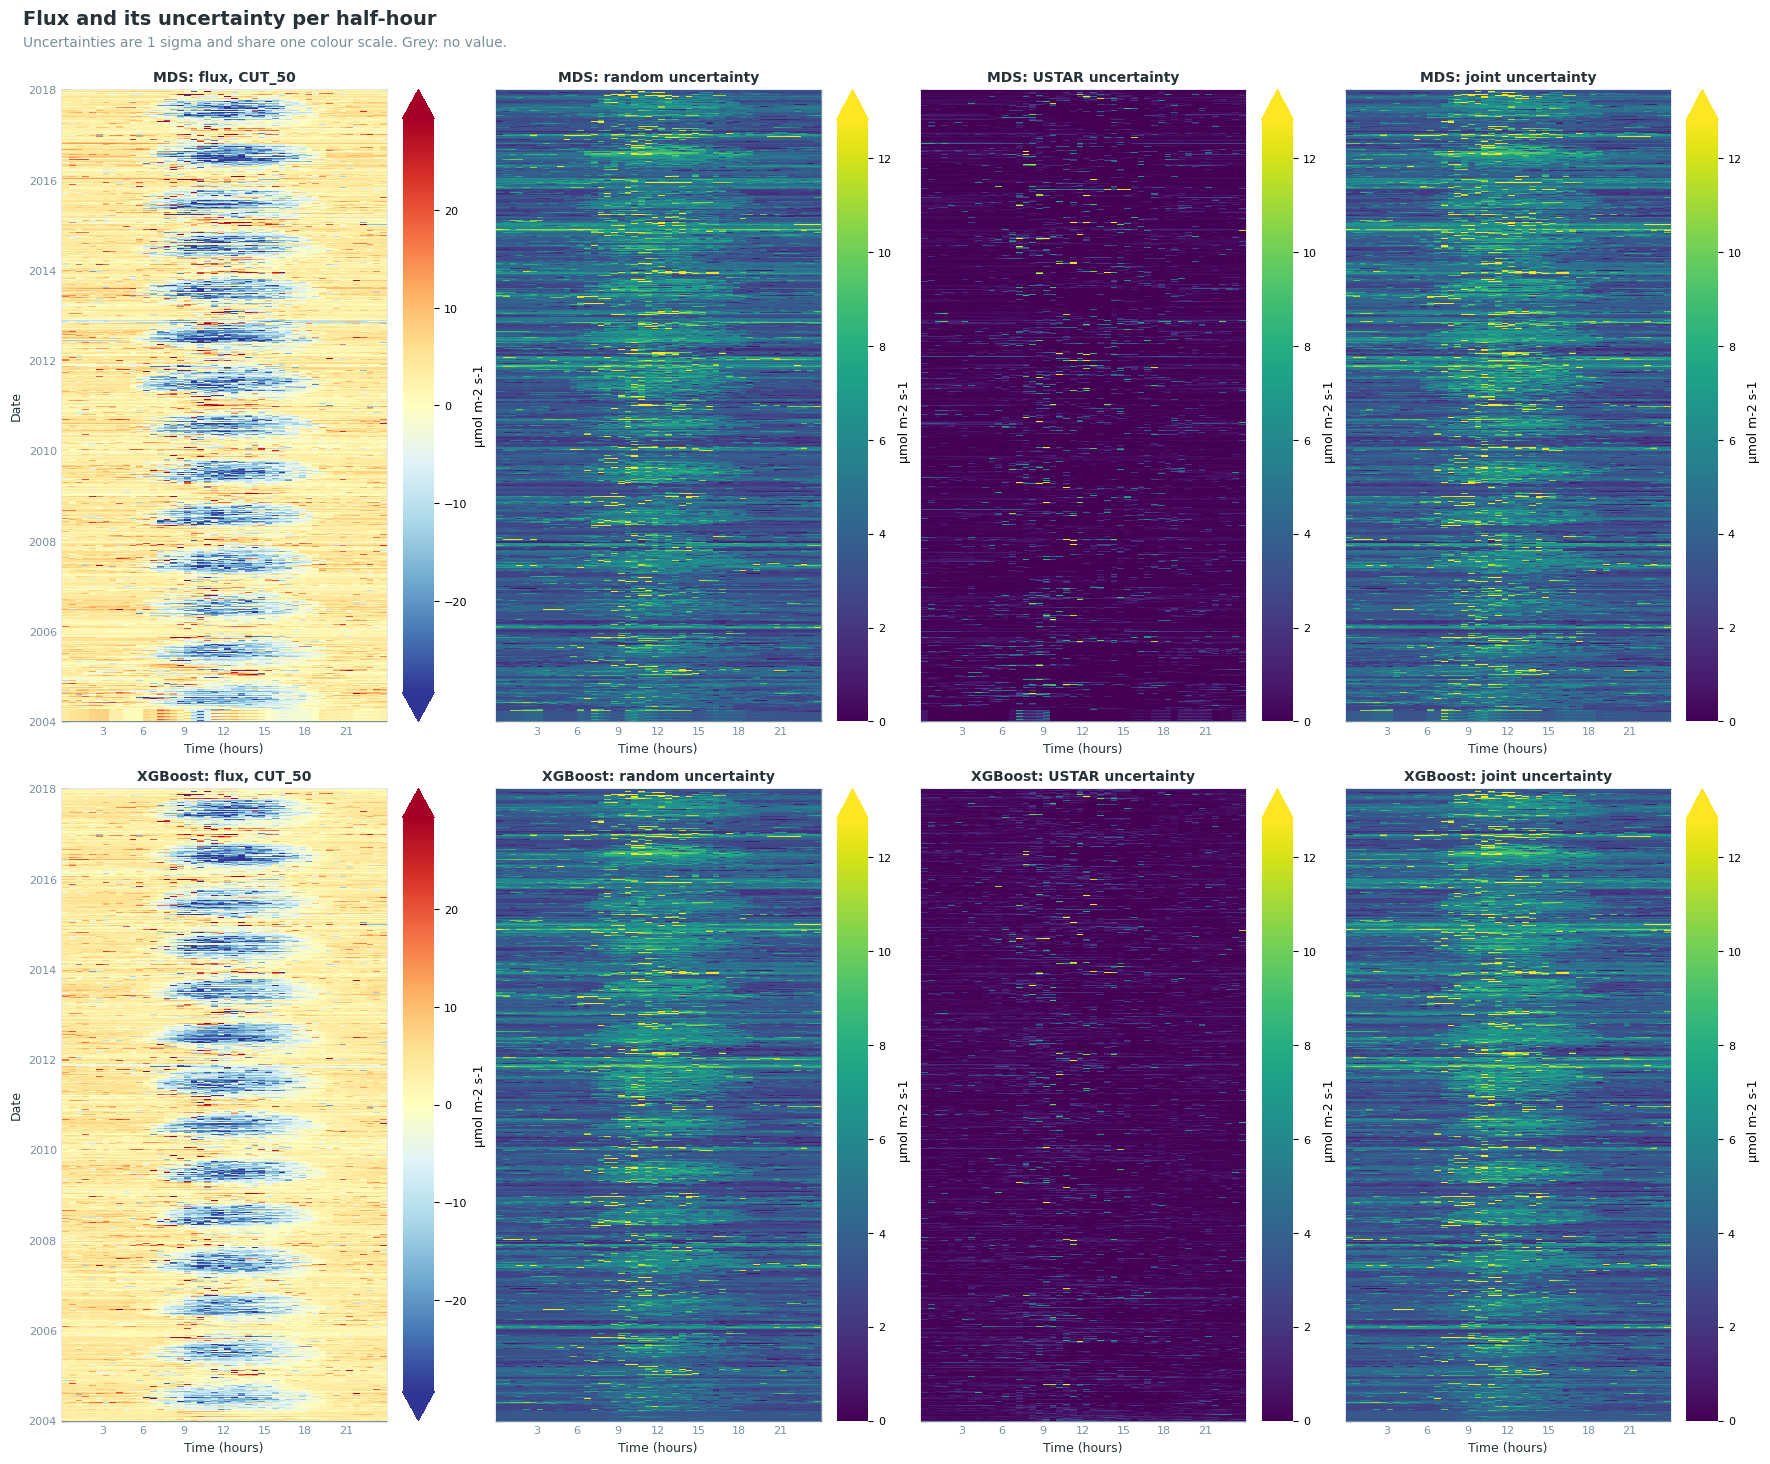

In [64]:
# The flux and its three uncertainties per half-hour. All fluxes share one colour scale, all
# uncertainties another.
_methods = list(UNC_FRAMES)
_flim = max(float(_m[GF_COLS[_k][UNC_REF]].abs().quantile(0.99)) for _k in _methods)
_ulim = max(float(UNC[_k][f'{GF_COLS[_k][UNC_REF]}_JOINTUNC'].quantile(0.99)) for _k in _methods)
fig, axs = plt.subplots(len(_methods), 4, figsize=(17.6, 7 * len(_methods) + 0.6), sharey=True,
                        layout='constrained', squeeze=False)
for _row, _method in zip(axs, _methods):
    _gf = GF_COLS[_method][UNC_REF]
    _name = METHOD_NAMES.get(_method, _method)
    _panels = [
        (f'{_name}: flux, {UNC_REF}', _m[_gf], cp.HEATMAP_CMAP, -_flim, _flim, 'both'),
        (f'{_name}: random uncertainty', UNC[_method][f'{_gf}_RANDUNC'], 'viridis', 0, _ulim, 'max'),
        (f'{_name}: USTAR uncertainty', UNC[_method][f'{_gf}_USTARUNC'], 'viridis', 0, _ulim, 'max'),
        (f'{_name}: joint uncertainty', UNC[_method][f'{_gf}_JOINTUNC'], 'viridis', 0, _ulim, 'max'),
    ]
    for _j, (_ax, (_title, _series, _cmap, _vmin, _vmax, _extend)) in enumerate(zip(_row, _panels)):
        dv.plotting.HeatmapDateTime(series=_series, verbose=False).plot(
            ax=_ax, fig=fig, vmin=_vmin, vmax=_vmax, cmap=_cmap, cb_extend=_extend,
            cb_digits_after_comma='auto', cb_labelsize=8, zlabel=FLUX_UNITS,
            color_bad=cp.NAN_COLOR, as_image=True, format_style=cp.heatmap_style(_title))
        # The unit label next to its colour bar, not halfway to the next panel.
        _cb = _ax.images[-1].colorbar if _ax.images else None
        if _cb is not None:
            _cb.set_label(FLUX_UNITS, size=9, labelpad=4)
        if _j:
            plt.setp(_ax.get_yticklabels(), visible=False)
            _ax.yaxis.get_label().set_visible(False)
cp.figure_title(fig, 'Flux and its uncertainty per half-hour',
                'Uncertainties are 1 sigma and share one colour scale. Grey: no value.')
plt.show()

## 💾 Step 13: export

The output file holds only what this notebook adds: every column the chain created and the three
uncertainty columns of Step 12 for each gap-filling method. The input columns stay unchanged in the
input file; the merge into the fullset joins the outputs of the flux notebooks with it on the
timestamp.

In [65]:
# Only the new columns: the input columns are in the input file and are added back in the merge.
_all = data.merged_df().join(UNC_EXPORT)
out_df = _all[[c for c in _all.columns if c not in df.columns]]
assert out_df.index.equals(df.index), "the output timestamps differ from the input"
assert set(UNC_EXPORT.columns) <= set(out_df.columns), "uncertainty columns missing from the output"
print(f"Uncertainty columns in the output: {list(UNC_EXPORT.columns)}")
print(f"{out_df.shape[0]:,} records x {out_df.shape[1]} columns (input columns left out: "
      f"{_all.shape[1] - out_df.shape[1]})")
filepath = dv.save_parquet(data=out_df, filename=OUTNAME, outpath=OUTPATH)

> New variables from the flux post-processing chain: 111 (L2: 12, L3.1: 9, L3.2: 12, L3.3: 21, 
L4.1: 12, L4.2: 42, other: 3)

> No variables in the input data were overwritten, only new variables added.

Uncertainty columns in the output: ['NEE_L3.1_L3.3_CUT_50_QCF_gfMDS_RANDUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfMDS_USTARUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfMDS_JOINTUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG_RANDUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG_USTARUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG_JOINTUNC']
245,472 records x 122 columns (input columns left out: 348)


> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA75\05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet (1.433 seconds).

***

# End of notebook.

In [66]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-30 08:54:14
Finished: 2026-10-30 09:25:24
Runtime:  00:31:09 (hh:mm:ss)
